In [ ]:
!nvidia-smi
import torch
print('torch', torch.__version__, '| cuda:', torch.version.cuda, '| available:', torch.cuda.is_available())

Thu Nov 12 16:39:05 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   44C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
os.makedirs('/content/drive/MyDrive/ccreid/runs', exist_ok=True)
os.makedirs('/content/drive/MyDrive/ccreid/results', exist_ok=True)
os.makedirs('/content/cc-reid-uncertainty/reid', exist_ok=True)
os.chdir('/content/cc-reid-uncertainty')
# runs/ aur results/ Drive mein save hon, taake session toote toh kuch na jaye
os.system('ln -sfn /content/drive/MyDrive/ccreid/runs runs')
os.system('ln -sfn /content/drive/MyDrive/ccreid/results results')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


0

In [ ]:
import os, sys
if not os.path.isdir('/content/deep-person-reid'):
    os.system('git clone https://github.com/KaiyangZhou/deep-person-reid.git /content/deep-person-reid')
os.system('pip install -q yacs gdown h5py tensorboard')
# setup.py develop ki jagah path se use karo (Python 3.13 par setup.py toot-ta hai)
os.environ['PYTHONPATH'] = '/content/deep-person-reid:' + os.environ.get('PYTHONPATH', '')
sys.path.insert(0, '/content/deep-person-reid')
import torchreid
print('torchreid OK', torchreid.__version__)
os.chdir('/content/cc-reid-uncertainty')

/content/deep-person-reid/torchreid/metrics/rank.py:11: UserWarning: Cython evaluation (very fast so highly recommended) is unavailable, now use python evaluation.
  warnings.warn(


torchreid OK 1.4.0


In [ ]:
%%writefile reid/__init__.py

Overwriting reid/__init__.py


In [ ]:
%%writefile reid/datasets.py
"""Dataset parsers (pure python, no torch). PRCC + Market-1501.

Every parser returns a dict:
    train, query, gallery : list of (path, pid, camid, clothes_id)   (all ints except path)
    num_train_pids        : number of train identities (train pids are relabelled 0..N-1)

clothes_id is an integer that is unique per (identity, outfit). Market-1501 has no
clothes labels, so every image gets clothes_id 0 there.
"""
import os
import re

IMG_EXT = ('.jpg', '.jpeg', '.png', '.bmp')


def _imgs(folder):
    if not os.path.isdir(folder):
        raise FileNotFoundError(f'folder not found: {folder}')
    out = []
    for r, _, fs in os.walk(folder):
        out += [os.path.join(r, f) for f in fs if f.lower().endswith(IMG_EXT)]
    return sorted(out)


class _Ids:
    """key -> contiguous int id"""

    def __init__(self):
        self.m = {}

    def __call__(self, key):
        return self.m.setdefault(key, len(self.m))


def relabel_train(items):
    pids = sorted({it[1] for it in items})
    mp = {p: i for i, p in enumerate(pids)}
    return [(path, mp[pid], cam, clo) for path, pid, cam, clo in items], len(pids)


def _pack(train, query, gallery):
    train, n = relabel_train(train)
    return dict(train=train, query=query, gallery=gallery, num_train_pids=n)


# ---------------------------------------------------------------- PRCC
def load_prcc(root):
    """PRCC layout: root/rgb/{train,val,test}/{A,B,C}/<pid>/*.jpg
    A and B: same clothes.  C: different clothes.
    gallery = test/A, query = test/B (same clothes) + test/C (clothes changed).
    """
    base = os.path.join(root, 'rgb')
    if not os.path.isdir(base):
        base = root
    cams = {'A': 0, 'B': 1, 'C': 2}
    clo = _Ids()

    def parse(split, letters):
        items = []
        for L in letters:
            cdir = os.path.join(base, split, L)
            if not os.path.isdir(cdir):
                raise FileNotFoundError(f'folder not found: {cdir}')
            for pid_dir in sorted(os.listdir(cdir)):
                sub = os.path.join(cdir, pid_dir)
                if not os.path.isdir(sub):
                    continue
                pid = int(pid_dir)
                c = clo((pid, 1 if L == 'C' else 0))
                items += [(p, pid, cams[L], c) for p in _imgs(sub)]
        return items

    return _pack(parse('train', 'ABC'), parse('test', 'BC'), parse('test', 'A'))


# ---------------------------------------------------------------- Market-1501
def load_market(root):
    """Market-1501 layout: root/{bounding_box_train,bounding_box_test,query}/0002_c1s1_000451_03.jpg"""
    if not os.path.isdir(os.path.join(root, 'bounding_box_train')):
        subs = [d for d in os.listdir(root)
                if os.path.isdir(os.path.join(root, d, 'bounding_box_train'))]
        if subs:
            root = os.path.join(root, subs[0])
    pat = re.compile(r'(-?\d+)_c(\d)')

    def parse(folder):
        items = []
        for path in _imgs(os.path.join(root, folder)):
            m = pat.search(os.path.basename(path))
            if m is None:
                raise ValueError(f'Market: cannot parse {path}')
            pid, cam = int(m.group(1)), int(m.group(2))
            if pid == -1:          # junk images
                continue
            items.append((path, pid, cam - 1, 0))
        return items

    return _pack(parse('bounding_box_train'), parse('query'), parse('bounding_box_test'))


LOADERS = {'prcc': load_prcc, 'market': load_market}
# which evaluation settings make sense for which dataset (see metrics.build_keep)
SETTINGS = {'prcc': ['sc', 'cc'], 'market': ['general']}
# PRCC is evaluated single-shot (one random gallery image per identity), repeated
SINGLE_SHOT = {'prcc': True, 'market': False}


def load_dataset(name, root):
    return LOADERS[name](root)


def summary(data):
    lines = []
    for split in ('train', 'query', 'gallery'):
        it = data[split]
        lines.append(f'  {split:8s} images={len(it):6d}  ids={len({x[1] for x in it}):4d}  '
                     f'cams={len({x[2] for x in it})}  outfits={len({x[3] for x in it})}')
    return '\n'.join(lines)

Overwriting reid/datasets.py


In [ ]:
%%writefile reid/metrics.py
"""Ranking metrics + per-query records for the confidence analysis (numpy only)."""
import numpy as np


def build_keep(q, g, setting):
    """q, g: int arrays (n, 3) = [pid, cam, clothes].  Returns bool (nq, ng): True = gallery item is used.

    Always removed: same identity AND same camera (standard Re-ID protocol).
      'general': nothing more.
      'sc'  (same-clothes):    also remove same identity with DIFFERENT clothes
                               -> true matches are same person, same clothes
      'cc'  (clothes-changing): also remove same identity with SAME clothes
                               -> true matches are same person, different clothes
    Queries that end up with no true match are skipped by rank_records.
    """
    same_pid = q[:, 0][:, None] == g[:, 0][None, :]
    same_cam = q[:, 1][:, None] == g[:, 1][None, :]
    same_clo = q[:, 2][:, None] == g[:, 2][None, :]
    remove = same_pid & same_cam
    if setting == 'sc':
        remove |= same_pid & ~same_clo
    elif setting == 'cc':
        remove |= same_pid & same_clo
    elif setting != 'general':
        raise ValueError(setting)
    return ~remove


def rank_records(sim, q_pid, g_pid, keep, max_rank=20):
    """sim: (nq, ng) similarity, higher = better.
    Returns dict of per-query arrays:
      correct   : bool, rank-1 hit
      top1_sim  : similarity of the best gallery item           (confidence score 1)
      margin    : top1_sim - best sim of a DIFFERENT identity   (confidence score 2)
      ap        : average precision
      cmc       : (n, max_rank) 0/1
    """
    correct, top1, margin, ap, cmc = [], [], [], [], []
    for i in range(sim.shape[0]):
        k = keep[i]
        gp = g_pid[k]
        if not (gp == q_pid[i]).any():
            continue
        s = sim[i][k]
        order = np.argsort(-s, kind='stable')
        s, gp = s[order], gp[order]
        hit = gp == q_pid[i]
        first = int(np.argmax(hit))
        c = np.zeros(max_rank)
        if first < max_rank:
            c[first:] = 1
        pos = np.where(hit)[0]
        ap.append(float(((np.arange(len(pos)) + 1) / (pos + 1)).mean()))
        cmc.append(c)
        correct.append(bool(hit[0]))
        top1.append(float(s[0]))
        other = gp != gp[0]
        margin.append(float(s[0] - (s[other][0] if other.any() else s.min())))
    return dict(correct=np.array(correct, bool), top1_sim=np.array(top1),
                margin=np.array(margin), ap=np.array(ap),
                cmc=np.array(cmc).reshape(-1, max_rank))


def summarize(rec):
    n = len(rec['ap'])
    if n == 0:
        return dict(n_queries=0)
    cmc = rec['cmc'].mean(0)
    return dict(n_queries=n, rank1=100 * cmc[0], rank5=100 * cmc[4], rank10=100 * cmc[9],
                mAP=100 * rec['ap'].mean())


def concat_records(recs):
    return {k: np.concatenate([r[k] for r in recs]) for k in recs[0]}

Overwriting reid/metrics.py


In [ ]:
%%writefile reid/loader.py
"""torch data pipeline: transforms, dataset, PK batch sampler."""
from collections import defaultdict

import numpy as np
import torch
from PIL import Image
from torch.utils.data import DataLoader, Dataset, Sampler
import torchvision.transforms as T

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
H, W = 256, 128


def train_transform(color_aug=False):
    t = [T.Resize((H, W)), T.RandomHorizontalFlip(), T.Pad(10), T.RandomCrop((H, W))]
    if color_aug:   # makes the model rely less on clothes colour
        t += [T.ColorJitter(0.4, 0.4, 0.4, 0.1), T.RandomGrayscale(p=0.2)]
    t += [T.ToTensor(), T.Normalize(MEAN, STD), T.RandomErasing(p=0.5, value='random')]
    return T.Compose(t)


def eval_transform():
    return T.Compose([T.Resize((H, W)), T.ToTensor(), T.Normalize(MEAN, STD)])


class ReIDDataset(Dataset):
    def __init__(self, items, transform):
        self.items, self.transform = items, transform

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        path, pid, cam, _ = self.items[i]
        img = Image.open(path).convert('RGB')
        return self.transform(img), pid, cam


class PKBatchSampler(Sampler):
    """Each batch: P random identities x K random images. `iters` batches per epoch."""

    def __init__(self, labels, P, K, iters, seed=0):
        self.index = defaultdict(list)
        for i, l in enumerate(labels):
            self.index[l].append(i)
        self.pids = list(self.index)
        self.P, self.K, self.iters, self.seed, self.epoch = P, K, iters, seed, 0

    def __len__(self):
        return self.iters

    def __iter__(self):
        rng = np.random.default_rng(self.seed + self.epoch)
        self.epoch += 1
        for _ in range(self.iters):
            pids = rng.choice(self.pids, self.P, replace=len(self.pids) < self.P)
            batch = []
            for p in pids:
                idx = self.index[p]
                batch += list(rng.choice(idx, self.K, replace=len(idx) < self.K))
            yield [int(b) for b in batch]


def make_train_loader(items, P=16, K=4, color_aug=False, workers=4, seed=0):
    ds = ReIDDataset(items, train_transform(color_aug))
    iters = max(len(items) // (P * K), 1)
    bs = PKBatchSampler([x[1] for x in items], P, K, iters, seed)
    return DataLoader(ds, batch_sampler=bs, num_workers=workers, pin_memory=True)


def make_eval_loader(items, bs=128, workers=4):
    return DataLoader(ReIDDataset(items, eval_transform()), batch_size=bs, shuffle=False,
                      num_workers=workers, pin_memory=True)

Overwriting reid/loader.py


In [ ]:
%%writefile reid/model.py
"""OSNet (via Torchreid) + losses."""
import torch
import torch.nn as nn
import torch.nn.functional as F


def build_model(num_classes, pretrained=True):
    """OSNet-x1.0. train mode -> (logits, 512-d feature); eval mode -> 512-d feature.
    If the automatic ImageNet-weight download fails, download the weights by hand and pass
    pretrained=False, then use torchreid.utils.load_pretrained_weights(model, path).
    """
    import torchreid
    return torchreid.models.build_model(name='osnet_x1_0', num_classes=num_classes,
                                        loss='triplet', pretrained=pretrained)


class LabelSmoothCE(nn.Module):
    def __init__(self, eps=0.1):
        super().__init__()
        self.eps = eps

    def forward(self, logits, target):
        logp = F.log_softmax(logits, dim=1)
        n = logits.size(1)
        nll = -logp.gather(1, target[:, None]).squeeze(1)
        smooth = -logp.mean(1)
        return ((1 - self.eps) * nll + self.eps * smooth).mean()


def batch_hard_triplet(feat, labels, margin=0.3):
    """Hardest positive / hardest negative per anchor, on L2-normalised features."""
    feat = F.normalize(feat, dim=1)
    dist = torch.sqrt(torch.clamp(2 - 2 * feat @ feat.t(), min=1e-12))
    same = labels[:, None] == labels[None, :]
    pos = dist.masked_fill(~same, float('-inf')).max(1).values
    neg = dist.masked_fill(same, float('inf')).min(1).values
    return F.relu(pos - neg + margin).mean()

Overwriting reid/model.py


In [ ]:
%%writefile train.py
"""Fine-tune OSNet on one dataset.   python train.py --dataset prcc --root /content/data/prcc --seed 0
No checkpoint selection on the test set: the LAST epoch is saved and evaluated."""
import argparse
import csv
import math
import os
import random
import time

import numpy as np
import torch

from reid.datasets import load_dataset, summary
from reid.loader import make_train_loader
from reid.model import LabelSmoothCE, batch_hard_triplet, build_model


def get_args():
    p = argparse.ArgumentParser()
    p.add_argument('--dataset', required=True, choices=['prcc', 'market'])
    p.add_argument('--root', required=True)
    p.add_argument('--seed', type=int, default=0)
    p.add_argument('--epochs', type=int, default=60)
    p.add_argument('--warmup', type=int, default=5)
    p.add_argument('--P', type=int, default=16)
    p.add_argument('--K', type=int, default=4)
    p.add_argument('--lr', type=float, default=3.5e-4)
    p.add_argument('--wd', type=float, default=5e-4)
    p.add_argument('--margin', type=float, default=0.3)
    p.add_argument('--smooth', type=float, default=0.1)
    p.add_argument('--color_aug', action='store_true')
    p.add_argument('--workers', type=int, default=4)
    p.add_argument('--out', default='runs')
    return p.parse_args()


def main():
    a = get_args()
    random.seed(a.seed); np.random.seed(a.seed); torch.manual_seed(a.seed)
    variant = 'coloraug' if a.color_aug else 'base'
    run = f'{a.dataset}_{variant}_s{a.seed}'
    out = os.path.join(a.out, run)
    os.makedirs(out, exist_ok=True)

    data = load_dataset(a.dataset, a.root)
    print(run, '\n' + summary(data))
    dev = 'cuda' if torch.cuda.is_available() else 'cpu'
    amp = dev == 'cuda'
    model = build_model(data['num_train_pids'], pretrained=True).to(dev)
    loader = make_train_loader(data['train'], a.P, a.K, a.color_aug, a.workers, a.seed)

    ce = LabelSmoothCE(a.smooth)
    opt = torch.optim.Adam(model.parameters(), lr=a.lr, weight_decay=a.wd)

    def lr_at(ep):  # linear warm-up, then cosine to 0
        if ep < a.warmup:
            return (ep + 1) / a.warmup
        return 0.5 * (1 + math.cos(math.pi * (ep - a.warmup) / max(a.epochs - a.warmup, 1)))

    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_at)
    scaler = torch.amp.GradScaler('cuda', enabled=amp)

    with open(os.path.join(out, 'log.csv'), 'w', newline='') as f:
        w = csv.writer(f); w.writerow(['epoch', 'loss', 'loss_id', 'loss_tri', 'acc', 'lr', 'sec'])
        for ep in range(a.epochs):
            model.train(); t0 = time.time()
            tot = dict(l=0., i=0., t=0., acc=0.); n = 0
            for imgs, pids, _ in loader:
                imgs, pids = imgs.to(dev), pids.to(dev)
                with torch.amp.autocast('cuda', enabled=amp):
                    logits, feat = model(imgs)
                li = ce(logits.float(), pids)
                lt = batch_hard_triplet(feat.float(), pids, a.margin)
                loss = li + lt
                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(opt); scaler.update()
                tot['l'] += loss.item(); tot['i'] += li.item(); tot['t'] += lt.item()
                tot['acc'] += (logits.argmax(1) == pids).float().mean().item(); n += 1
            sched.step()
            row = [ep + 1, tot['l'] / n, tot['i'] / n, tot['t'] / n, tot['acc'] / n,
                   opt.param_groups[0]['lr'], time.time() - t0]
            w.writerow(row); f.flush()
            print('ep %3d  loss %.3f (id %.3f tri %.3f)  acc %.3f  lr %.2e  %.0fs' % tuple(row))

    torch.save({'state': model.state_dict(), 'num_classes': data['num_train_pids'],
                'args': vars(a)}, os.path.join(out, 'last.pt'))
    print('saved', os.path.join(out, 'last.pt'))


if __name__ == '__main__':
    main()

Overwriting train.py


In [ ]:
%%writefile evaluate.py
"""Evaluate a trained run under the protocols of its dataset.
   python evaluate.py --run runs/prcc_base_s0 --root /content/data/prcc
Writes results/<run>_<setting>.json (metrics) and .npz (per-query records for confidence.py)"""
import argparse
import json
import os

import numpy as np
import torch
import torch.nn.functional as F

from reid.datasets import SETTINGS, SINGLE_SHOT, load_dataset, summary
from reid.loader import make_eval_loader
from reid.metrics import build_keep, concat_records, rank_records, summarize
from reid.model import build_model


@torch.no_grad()
def extract(model, items, dev, workers):
    model.eval(); feats = []
    for imgs, _, _ in make_eval_loader(items, workers=workers):
        imgs = imgs.to(dev)
        f = F.normalize(model(imgs).float(), dim=1) + F.normalize(model(torch.flip(imgs, [3])).float(), dim=1)
        feats.append(F.normalize(f, dim=1).cpu())
    return torch.cat(feats).numpy()


def meta(items):
    return np.array([[x[1], x[2], x[3]] for x in items], dtype=np.int64)


def one_shot_idx(g_pid, rng):
    return np.array([rng.choice(np.where(g_pid == p)[0]) for p in np.unique(g_pid)])


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument('--run', required=True)
    ap.add_argument('--root', required=True)
    ap.add_argument('--trials', type=int, default=10, help='gallery re-samplings (PRCC single-shot only)')
    ap.add_argument('--workers', type=int, default=4)
    ap.add_argument('--out', default='results')
    a = ap.parse_args()

    ck = torch.load(os.path.join(a.run, 'last.pt'), map_location='cpu')
    name = ck['args']['dataset']
    dev = 'cuda' if torch.cuda.is_available() else 'cpu'
    data = load_dataset(name, a.root)
    print(summary(data))
    model = build_model(ck['num_classes'], pretrained=False)
    model.load_state_dict(ck['state']); model.to(dev)

    qf, gf = extract(model, data['query'], dev, a.workers), extract(model, data['gallery'], dev, a.workers)
    sim = qf @ gf.T
    qm, gm = meta(data['query']), meta(data['gallery'])
    os.makedirs(a.out, exist_ok=True)
    tag = os.path.basename(os.path.normpath(a.run))
    trials = a.trials if SINGLE_SHOT[name] else 1

    for setting in SETTINGS[name]:
        recs, per_trial = [], []
        for t in range(trials):
            gi = one_shot_idx(gm[:, 0], np.random.default_rng(1000 + t)) if SINGLE_SHOT[name] \
                else np.arange(len(gm))
            keep = build_keep(qm, gm[gi], setting)
            r = rank_records(sim[:, gi], qm[:, 0], gm[gi, 0], keep)
            if len(r['ap']):
                recs.append(r); per_trial.append(summarize(r))
        if not recs:
            print(f'[{setting}] no valid queries, skipped'); continue
        res = {k: float(np.mean([p[k] for p in per_trial])) for k in per_trial[0]}
        res.update(dataset=name, setting=setting, trials=trials, run=tag)
        base = os.path.join(a.out, f'{tag}_{setting}')
        json.dump(res, open(base + '.json', 'w'), indent=1)
        np.savez(base + '.npz', **concat_records(recs))
        print(f"[{name}/{setting}] queries/trial={res['n_queries']:.0f}  Rank-1 {res['rank1']:.1f}  "
              f"Rank-5 {res['rank5']:.1f}  mAP {res['mAP']:.1f}")


if __name__ == '__main__':
    main()

Overwriting evaluate.py


In [ ]:
%%writefile check_dataset.py
"""Run this FIRST. Prints image / identity / camera / outfit counts so you can compare with the dataset paper."""
import argparse
from reid.datasets import load_dataset, summary

ap = argparse.ArgumentParser()
ap.add_argument('--dataset', required=True, choices=['prcc', 'market'])
ap.add_argument('--root', required=True)
a = ap.parse_args()
d = load_dataset(a.dataset, a.root)
print(a.dataset); print(summary(d))
print('train identities:', d['num_train_pids'])
print('example item:', d['query'][0])

Overwriting check_dataset.py


In [ ]:
%%writefile check_dataset.py
"""Run this FIRST. Prints image / identity / camera / outfit counts so you can compare with the dataset paper."""
import argparse
from reid.datasets import load_dataset, summary

ap = argparse.ArgumentParser()
ap.add_argument('--dataset', required=True, choices=['prcc', 'market'])
ap.add_argument('--root', required=True)
a = ap.parse_args()
d = load_dataset(a.dataset, a.root)
print(a.dataset); print(summary(d))
print('train identities:', d['num_train_pids'])
print('example item:', d['query'][0])

Overwriting check_dataset.py


In [ ]:
%%writefile report.py
"""Tables + figures for the README / SOP."""
import glob
import json
import os
from collections import defaultdict

import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

R = 'results'
os.makedirs(os.path.join(R, 'figures'), exist_ok=True)

# ---------- table 1: rank-1 / mAP mean±std over seeds
acc = defaultdict(lambda: defaultdict(list))
for f in glob.glob(os.path.join(R, '*_s*_*.json')):
    if f.endswith('confidence_summary.json'):
        continue
    d = json.load(open(f))
    ds, var = os.path.basename(f).split('_')[:2]
    for m in ('rank1', 'rank5', 'mAP'):
        acc[(ds, var, d['setting'])][m].append(d[m])
lines = ['| dataset | training | setting | Rank-1 | Rank-5 | mAP | seeds |', '|---|---|---|---|---|---|---|']
for (ds, var, st), v in sorted(acc.items()):
    cell = lambda m: f'{np.mean(v[m]):.1f} ± {np.std(v[m]):.1f}'
    lines.append(f'| {ds} | {var} | {st} | {cell("rank1")} | {cell("rank5")} | {cell("mAP")} | {len(v["rank1"])} |')
open(os.path.join(R, 'table_main.md'), 'w').write('\n'.join(lines) + '\n')
print('\n'.join(lines))

# ---------- fig 1: same-clothes vs clothes-changing
dss = sorted({k[0] for k in acc})
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for a, m, title in zip(ax, ('rank1', 'mAP'), ('Rank-1 (%)', 'mAP (%)')):
    w = 0.25
    for j, st in enumerate(('general', 'sc', 'cc')):
        xs, ys, es = [], [], []
        for i, ds in enumerate(dss):
            v = acc.get((ds, 'base', st))
            if v:
                xs.append(i + (j - 1) * w); ys.append(np.mean(v[m])); es.append(np.std(v[m]))
        a.bar(xs, ys, w, yerr=es, label=st)
    a.set_xticks(range(len(dss))); a.set_xticklabels(dss); a.set_title(title); a.legend(title='setting')
plt.tight_layout(); plt.savefig(os.path.join(R, 'figures', 'fig1_sc_vs_cc.png'), dpi=160); plt.close()

# ---------- fig 2/3: confidence
cf = os.path.join(R, 'confidence_summary.json')
if os.path.exists(cf):
    c = json.load(open(cf)); cov = c['coverage']
    keys = sorted({k.split('|')[0] for k in c['settings'] if k.split('|')[1] == 'base'})
    fig, axs = plt.subplots(1, len(keys), figsize=(4.6 * len(keys), 3.8), squeeze=False)
    for a, ds in zip(axs[0], keys):
        for st, col in (('sc', 'tab:blue'), ('cc', 'tab:red'), ('general', 'tab:green')):
            v = c['settings'].get(f'{ds}|base|{st}')
            if v:
                a.plot(cov, [100 * y for y in v['rc']], '-o', color=col, label=f'{st}')
                a.plot(cov, [100 * y for y in v['oracle']], ':', color=col, alpha=.6)
        a.set_xlabel('coverage (fraction of queries answered)'); a.set_ylabel('rank-1 accuracy (%)')
        a.set_title(f'{ds}: abstain curve (dotted = perfect abstain)'); a.invert_xaxis(); a.legend()
    plt.tight_layout(); plt.savefig(os.path.join(R, 'figures', 'fig2_abstain.png'), dpi=160); plt.close()

    fig, a = plt.subplots(figsize=(5.5, 3.6)); labels, vals, errs = [], [], []
    for k, v in sorted(c['settings'].items()):
        if k.split('|')[1] == 'base':
            labels.append(k.replace('|base|', '\n')); vals.append(v['auroc_top1']['mean']); errs.append(v['auroc_top1']['std'])
    a.bar(range(len(vals)), vals, yerr=errs); a.axhline(0.5, color='k', ls='--')
    a.set_xticks(range(len(vals))); a.set_xticklabels(labels, fontsize=8); a.set_ylim(0.4, 1)
    a.set_title('AUROC: does confidence separate right from wrong?')
    plt.tight_layout(); plt.savefig(os.path.join(R, 'figures', 'fig3_auroc.png'), dpi=160); plt.close()
print('figures ->', os.path.join(R, 'figures'))

Overwriting report.py


In [ ]:
import os
os.makedirs('/content/data', exist_ok=True)
os.system('pip install -q gdown')

# PRCC (authors ka Google Drive link)
!gdown 1yTYawRm4ap3M-j0PjLQJ--xmZHseFDLz -O /content/data/prcc.zip
!unzip -q -o /content/data/prcc.zip -d /content/data/

# Market-1501 (Google Drive mirror)
!gdown 0B8-rUzbwVRk0c054eEozWG9COHM -O /content/data/market.zip
!unzip -q -o /content/data/market.zip -d /content/data/

!ls /content/data

Downloading...
From (original): https://drive.google.com/uc?id=1yTYawRm4ap3M-j0PjLQJ--xmZHseFDLz
From (redirected): https://drive.google.com/uc?id=1yTYawRm4ap3M-j0PjLQJ--xmZHseFDLz&confirm=t&uuid=bb978f6c-58f0-4498-b9a9-41fdd5051966
To: /content/data/prcc.zip
100% 272M/272M [00:05<00:00, 53.9MB/s]
[/content/data/prcc.zip]
  End-of-central-directory signature not found.  Either this file is not
  a zipfile, or it constitutes one disk of a multi-part archive.  In the
  latter case the central directory and zipfile comment will be found on
  the last disk(s) of this archive.
unzip:  cannot find zipfile directory in one of /content/data/prcc.zip or
        /content/data/prcc.zip.zip, and cannot find /content/data/prcc.zip.ZIP, period.
Downloading...
From (original): https://drive.google.com/uc?id=0B8-rUzbwVRk0c054eEozWG9COHM
From (redirected): https://drive.google.com/uc?id=0B8-rUzbwVRk0c054eEozWG9COHM&confirm=t&uuid=3458deb6-cedc-438b-b846-795703235ea4
To: /content/data/market.zip
100% 15

In [ ]:
!file /content/data/prcc.zip
!ls -la /content/data/prcc.zip
!head -c 200 /content/data/prcc.zip | xxd | head -5

/content/data/prcc.zip: gzip compressed data, last modified: Sun Jan 19 22:48:49 2020, from Unix, original size modulo 2^32 354201600 gzip compressed data, reserved method, ASCII, has CRC, extra field, has comment, from FAT filesystem (MS-DOS, OS/2, NT), original size modulo 2^32 354201600
-rw-r--r-- 1 root root 272084813 Jan 19  2020 /content/data/prcc.zip
/bin/bash: line 1: xxd: command not found


In [ ]:
!mkdir -p /content/data/prcc_raw
!tar -xzf /content/data/prcc.zip -C /content/data/prcc_raw
!ls /content/data/prcc_raw
!ls /content/data/prcc_raw/* | head -20

prcc
rgb
sketch


In [ ]:
!python check_dataset.py --dataset market --root /content/data/Market-1501-v15.09.15

market
  train    images= 12936  ids= 751  cams=6  outfits=1
  query    images=  3368  ids= 750  cams=6  outfits=1
  gallery  images= 15913  ids= 751  cams=6  outfits=1
train identities: 751
example item: ('/content/data/Market-1501-v15.09.15/query/0001_c1s1_001051_00.jpg', 1, 0, 0)


In [ ]:
!ls /content/data/prcc_raw/prcc/rgb
!ls /content/data/prcc_raw/prcc/rgb/train | head -5
!ls /content/data/prcc_raw/prcc/rgb/train/$(ls /content/data/prcc_raw/prcc/rgb/train | head -1) | head -5
!ls /content/data/prcc_raw/prcc/rgb/test
!ls /content/data/prcc_raw/prcc/rgb/test/A | head -3

test  train  val
092
095
098
102
104
A_cropped_rgb001.jpg
A_cropped_rgb004.jpg
A_cropped_rgb007.jpg
A_cropped_rgb010.jpg
A_cropped_rgb013.jpg
A  B  C
001
002
004


In [ ]:
import re
s = open('reid/datasets.py').read()
start = s.index('# ---------------------------------------------------------------- PRCC')
end = s.index('# ---------------------------------------------------------------- Market-1501')
new = '''# ---------------------------------------------------------------- PRCC
def load_prcc(root):
    """PRCC: root/rgb/{train,val,test}/...
    test : test/{A,B,C}/<pid>/*.jpg
    train: train/<pid>/{A,B,C}_*.jpg  (camera = first letter of file name)  OR  train/{A,B,C}/<pid>/*.jpg
    A and B: same clothes.  C: different clothes.
    gallery = test/A, query = test/B (same clothes) + test/C (clothes changed).
    """
    base = os.path.join(root, 'rgb')
    if not os.path.isdir(base):
        base = root
    cams = {'A': 0, 'B': 1, 'C': 2}
    clo = _Ids()

    def parse(split, letters):
        d = os.path.join(base, split)
        if not os.path.isdir(d):
            raise FileNotFoundError(f'folder not found: {d}')
        items = []
        if os.path.isdir(os.path.join(d, 'A')):          # layout 1: split/{A,B,C}/<pid>
            for L in letters:
                cdir = os.path.join(d, L)
                if not os.path.isdir(cdir):
                    raise FileNotFoundError(f'folder not found: {cdir}')
                for pid_dir in sorted(os.listdir(cdir)):
                    sub = os.path.join(cdir, pid_dir)
                    if os.path.isdir(sub):
                        pid = int(pid_dir)
                        c = clo((pid, 1 if L == 'C' else 0))
                        items += [(p, pid, cams[L], c) for p in _imgs(sub)]
        else:                                            # layout 2: split/<pid>/<L>_*.jpg
            for pid_dir in sorted(os.listdir(d)):
                sub = os.path.join(d, pid_dir)
                if not os.path.isdir(sub):
                    continue
                pid = int(pid_dir)
                for p in _imgs(sub):
                    L = os.path.basename(p)[0].upper()
                    if L in letters:
                        items.append((p, pid, cams[L], clo((pid, 1 if L == 'C' else 0))))
        return items

    return _pack(parse('train', 'ABC'), parse('test', 'BC'), parse('test', 'A'))


'''
open('reid/datasets.py', 'w').write(s[:start] + new + s[end:])
print('patched')

patched


In [ ]:
!python check_dataset.py --dataset prcc --root /content/data/prcc_raw/prcc

prcc
  train    images= 17896  ids= 150  cams=3  outfits=300
  query    images=  7416  ids=  71  cams=2  outfits=142
  gallery  images=  3384  ids=  71  cams=1  outfits=71
train identities: 150
example item: ('/content/data/prcc_raw/prcc/rgb/test/B/001/cropped_rgb001.jpg', 1, 1, 300)


In [ ]:
!nvidia-smi
import torch
print('torch', torch.__version__, '| built with cuda:', torch.version.cuda)

Thu Nov 12 16:40:52 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   45C    P8             14W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
!python train.py --dataset prcc --root /content/data/prcc_raw/prcc --seed 0 --epochs 5
!python evaluate.py --run runs/prcc_base_s0 --root /content/data/prcc_raw/prcc

prcc_base_s0 
  train    images= 17896  ids= 150  cams=3  outfits=300
  query    images=  7416  ids=  71  cams=2  outfits=142
  gallery  images=  3384  ids=  71  cams=1  outfits=71
/content/deep-person-reid/torchreid/metrics/rank.py:11: UserWarning: Cython evaluation (very fast so highly recommended) is unavailable, now use python evaluation.
  warnings.warn(
I0000 00:00:1794501663.709899   16870 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Successfully loaded imagenet pretrained weights from "/root/.cache/torch/checkpoints/osnet_x1_0_imagenet.pth"
** The following layers are discarded due to unmatched keys or layer size: ['classifier.weight', 'classifier.bias']
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that

In [ ]:
import torch
print('GPU:', torch.cuda.is_available())

PRCC = '/content/data/prcc_raw/prcc'
!python train.py --dataset prcc --root {PRCC} --seed 0 --epochs 30 --workers 2
!python evaluate.py --run runs/prcc_base_s0 --root {PRCC} --workers 2

GPU: True
prcc_base_s0 
  train    images= 17896  ids= 150  cams=3  outfits=300
  query    images=  7416  ids=  71  cams=2  outfits=142
  gallery  images=  3384  ids=  71  cams=1  outfits=71
/content/deep-person-reid/torchreid/metrics/rank.py:11: UserWarning: Cython evaluation (very fast so highly recommended) is unavailable, now use python evaluation.
  warnings.warn(
I0000 00:00:1794502139.014323   18991 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Successfully loaded imagenet pretrained weights from "/root/.cache/torch/checkpoints/osnet_x1_0_imagenet.pth"
** The following layers are discarded due to unmatched keys or layer size: ['classifier.weight', 'classifier.bias']
ep   1  loss 5.085 (id 4.690 tri 0.395)  acc 0.181  lr 1.40e-04  69s
ep   2  loss 3.407 (id 3.130 tri 0.278)  acc 0.719  lr 2.10e-04  69s
ep   3  loss 1.652 (id 1.522 tri 0.130)  acc 0.939  lr 2.80e-04  67s
ep   4  loss 1.114 (id 1.048 tri 0.066)  acc 0.980  lr 3.50e-04  70s
ep

In [ ]:
PRCC = '/content/data/prcc_raw/prcc'
MARKET = '/content/data/Market-1501-v15.09.15'

# PRCC: colour-aug variant
!python train.py --dataset prcc --root {PRCC} --seed 0 --epochs 30 --color_aug --workers 2
!python evaluate.py --run runs/prcc_coloraug_s0 --root {PRCC} --workers 2

# PRCC: doosra seed (std nikalne ke liye)
!python train.py --dataset prcc --root {PRCC} --seed 1 --epochs 30 --workers 2
!python evaluate.py --run runs/prcc_base_s1 --root {PRCC} --workers 2

# Market-1501 (clothes-change ke baghair control)
!python train.py --dataset market --root {MARKET} --seed 0 --epochs 30 --workers 2
!python evaluate.py --run runs/market_base_s0 --root {MARKET} --workers 2

prcc_coloraug_s0 
  train    images= 17896  ids= 150  cams=3  outfits=300
  query    images=  7416  ids=  71  cams=2  outfits=142
  gallery  images=  3384  ids=  71  cams=1  outfits=71
/content/deep-person-reid/torchreid/metrics/rank.py:11: UserWarning: Cython evaluation (very fast so highly recommended) is unavailable, now use python evaluation.
  warnings.warn(
I0000 00:00:1794504321.850271   28302 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Successfully loaded imagenet pretrained weights from "/root/.cache/torch/checkpoints/osnet_x1_0_imagenet.pth"
** The following layers are discarded due to unmatched keys or layer size: ['classifier.weight', 'classifier.bias']
ep   1  loss 5.215 (id 4.799 tri 0.415)  acc 0.112  lr 1.40e-04  118s
ep   2  loss 3.878 (id 3.534 tri 0.344)  acc 0.593  lr 2.10e-04  118s
ep   3  loss 2.073 (id 1.868 tri 0.205)  acc 0.881  lr 2.80e-04  115s
ep   4  loss 1.314 (id 1.194 tri 0.120)  acc 0.954  lr 3.50e-04  116s
ep  

In [ ]:
"""Confidence / uncertainty analysis. Reads results/*_s<seed>_<setting>.npz (written by evaluate.py)
and writes results/confidence_summary.json (used by report.py for fig2 + fig3).
   python confidence.py"""
import glob
import json
import os
from collections import defaultdict

import numpy as np
from scipy.stats import rankdata

R = 'results'
COVERAGE = [1.0, 0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3, 0.2, 0.1]


def auroc(score, correct):
    """P(score of a correct query > score of a wrong query). 0.5 = useless, 1.0 = perfect."""
    pos, neg = int(correct.sum()), int((~correct).sum())
    if pos == 0 or neg == 0:
        return float('nan')
    r = rankdata(score)
    return float((r[correct].sum() - pos * (pos + 1) / 2) / (pos * neg))


def risk_coverage(score, correct):
    """Answer only the most-confident fraction of queries; return rank-1 acc at each coverage."""
    order = np.argsort(-score, kind='stable')
    c = correct[order]
    return [float(c[:max(1, int(round(f * len(c))))].mean()) for f in COVERAGE]


groups = defaultdict(list)
for f in sorted(glob.glob(os.path.join(R, '*_s*_*.npz'))):
    base = os.path.basename(f)[:-4]                 # e.g. prcc_base_s0_cc
    ds, var, _, setting = base.split('_')[:4]
    groups[f'{ds}|{var}|{setting}'].append(dict(np.load(f)))

out = dict(coverage=COVERAGE, settings={})
for key, runs in sorted(groups.items()):
    a1, am, rc = [], [], []
    for d in runs:
        ok = d['correct'].astype(bool)
        a1.append(auroc(d['top1_sim'], ok)); am.append(auroc(d['margin'], ok))
        rc.append(risk_coverage(d['margin'], ok))
    acc = float(np.mean([d['correct'].mean() for d in runs]))
    st = lambda x: dict(mean=float(np.nanmean(x)), std=float(np.nanstd(x)))
    out['settings'][key] = dict(
        n_runs=len(runs), rank1=acc,
        auroc_top1=st(a1), auroc_margin=st(am),
        rc=[float(x) for x in np.mean(rc, 0)],
        oracle=[min(1.0, acc / f) for f in COVERAGE])   # perfect abstention upper bound
    print(f"{key:22s} runs={len(runs)}  rank1={100*acc:5.1f}  "
          f"AUROC(top1)={out['settings'][key]['auroc_top1']['mean']:.3f}  "
          f"AUROC(margin)={out['settings'][key]['auroc_margin']['mean']:.3f}")

json.dump(out, open(os.path.join(R, 'confidence_summary.json'), 'w'), indent=1)
print('saved ->', os.path.join(R, 'confidence_summary.json'))

market|base|general    runs=1  rank1= 93.3  AUROC(top1)=0.750  AUROC(margin)=0.914
prcc|base|cc           runs=2  rank1= 38.6  AUROC(top1)=0.697  AUROC(margin)=0.770
prcc|base|sc           runs=2  rank1= 98.1  AUROC(top1)=0.973  AUROC(margin)=0.981
prcc|coloraug|cc       runs=1  rank1= 30.5  AUROC(top1)=0.721  AUROC(margin)=0.758
prcc|coloraug|sc       runs=1  rank1= 97.9  AUROC(top1)=0.926  AUROC(margin)=0.982
saved -> results/confidence_summary.json


| dataset | training | setting | Rank-1 | Rank-5 | mAP | seeds |
|---|---|---|---|---|---|---|
| market | base | general | 93.3 ± 0.0 | 97.5 ± 0.0 | 82.3 ± 0.0 | 1 |
| prcc | base | cc | 38.6 ± 2.2 | 58.8 ± 2.2 | 48.7 ± 2.0 | 2 |
| prcc | base | sc | 98.1 ± 0.2 | 99.7 ± 0.1 | 98.8 ± 0.0 | 2 |
| prcc | coloraug | cc | 30.5 ± 0.0 | 58.0 ± 0.0 | 43.9 ± 0.0 | 1 |
| prcc | coloraug | sc | 97.9 ± 0.0 | 99.7 ± 0.0 | 98.7 ± 0.0 | 1 |
figures -> results/figures


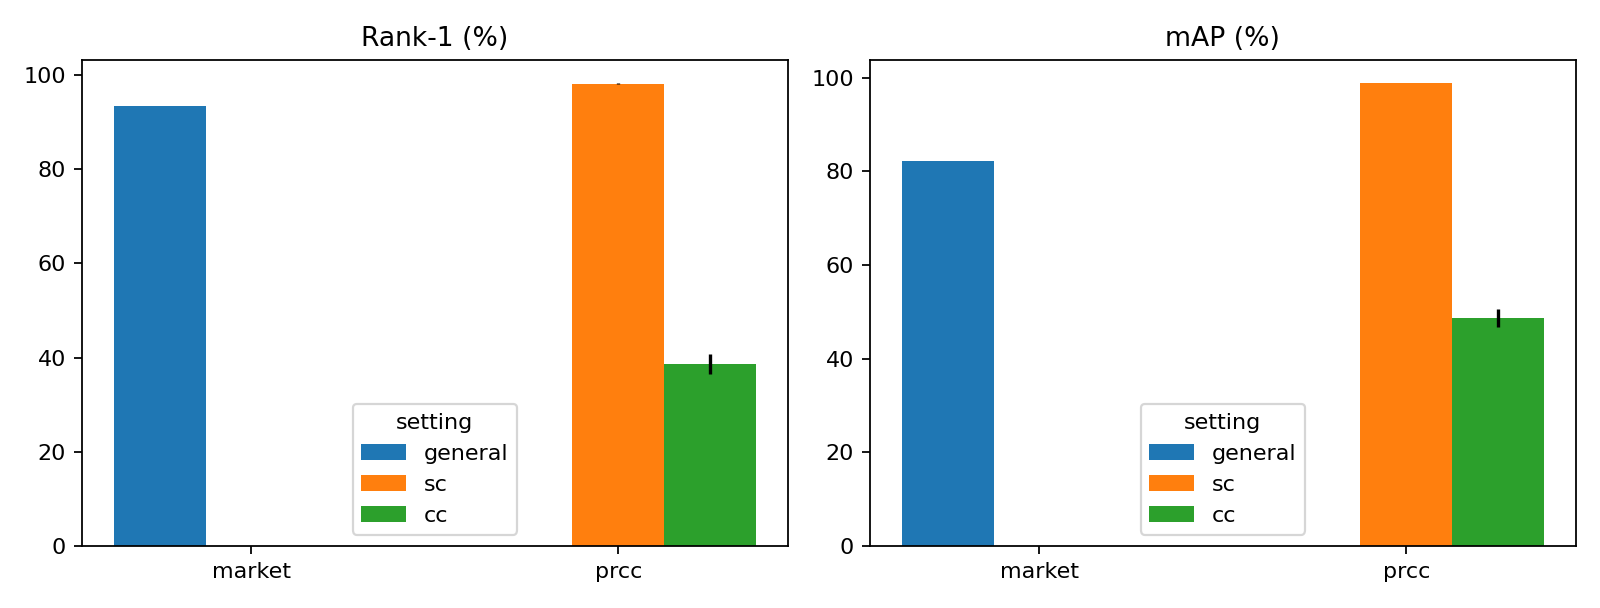

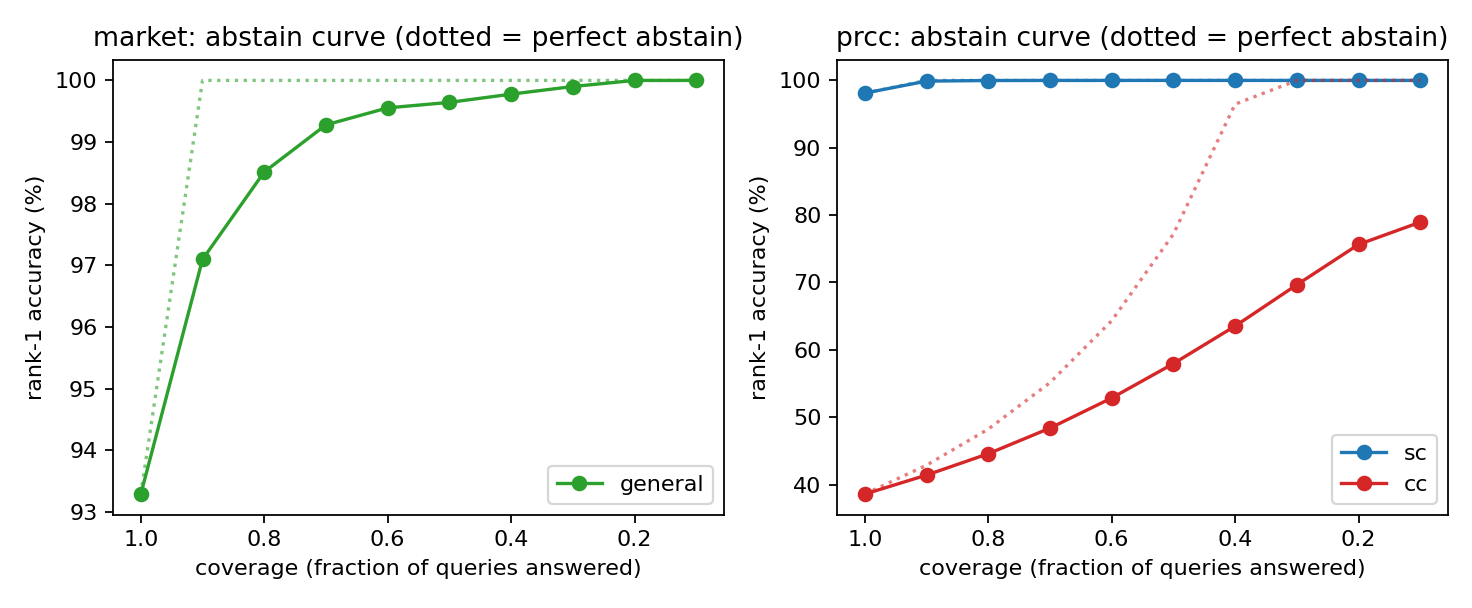

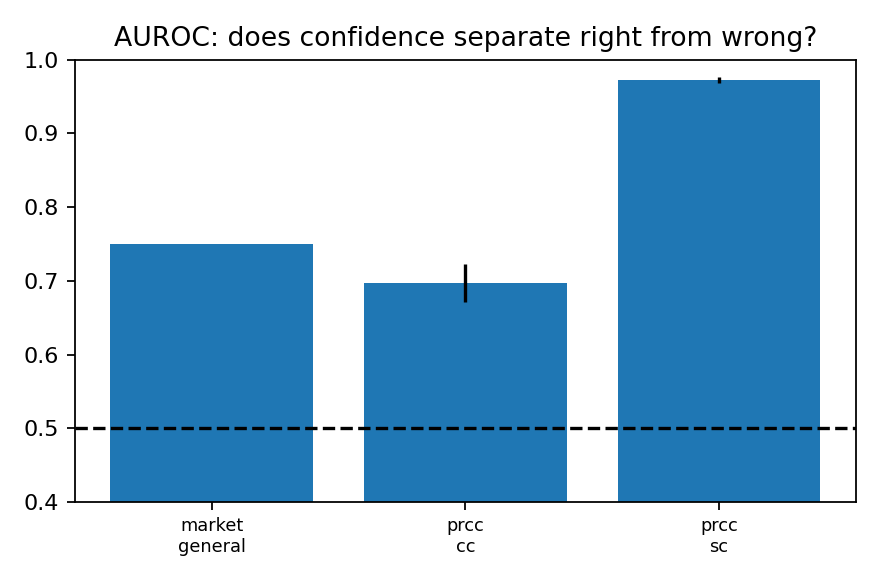

In [ ]:
!python report.py

from IPython.display import Image, display
for f in ['fig1_sc_vs_cc', 'fig2_abstain', 'fig3_auroc']:
    display(Image(f'results/figures/{f}.png'))

In [ ]:
!python confidence.py
!python report.py

python3: can't open file '/content/cc-reid-uncertainty/confidence.py': [Errno 2] No such file or directory
| dataset | training | setting | Rank-1 | Rank-5 | mAP | seeds |
|---|---|---|---|---|---|---|
| market | base | general | 93.3 ± 0.0 | 97.5 ± 0.0 | 82.3 ± 0.0 | 1 |
| prcc | base | cc | 38.6 ± 2.2 | 58.8 ± 2.2 | 48.7 ± 2.0 | 2 |
| prcc | base | sc | 98.1 ± 0.2 | 99.7 ± 0.1 | 98.8 ± 0.0 | 2 |
| prcc | coloraug | cc | 30.5 ± 0.0 | 58.0 ± 0.0 | 43.9 ± 0.0 | 1 |
| prcc | coloraug | sc | 97.9 ± 0.0 | 99.7 ± 0.0 | 98.7 ± 0.0 | 1 |
figures -> results/figures


In [ ]:

!zip -rq backup.zip results runs
from google.colab import files
files.download('backup.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

new model

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, sys
for d in ['runs', 'results', 'results_cross']:
    os.makedirs(f'/content/drive/MyDrive/ccreid/{d}', exist_ok=True)
os.makedirs('/content/cc-reid-uncertainty/reid', exist_ok=True)
os.chdir('/content/cc-reid-uncertainty')
for d in ['runs', 'results', 'results_cross']:
    os.system(f'ln -sfn /content/drive/MyDrive/ccreid/{d} {d}')

if not os.path.isdir('/content/deep-person-reid'):
    os.system('git clone https://github.com/KaiyangZhou/deep-person-reid.git /content/deep-person-reid')
os.system('pip install -q yacs gdown h5py tensorboard timm')
os.environ['PYTHONPATH'] = '/content/deep-person-reid:' + os.environ.get('PYTHONPATH', '')
sys.path.insert(0, '/content/deep-person-reid')
import torchreid
print('torchreid OK', torchreid.__version__)
print(os.listdir('runs'))     # purane runs yahan nazar aane chahiye

Mounted at /content/drive


/content/deep-person-reid/torchreid/metrics/rank.py:11: UserWarning: Cython evaluation (very fast so highly recommended) is unavailable, now use python evaluation.
  warnings.warn(


torchreid OK 1.4.0
['prcc_base_s0', 'prcc_coloraug_s0', 'prcc_base_s1', 'market_base_s0', 'prcc_osnetain_s0', 'market_osnetain_s0', 'prcc_resnet50_s0', 'market_resnet50_s0', 'prcc_densenet121_s0', 'market_densenet121_s0']


In [ ]:
%%writefile reid/__init__.py

Writing reid/__init__.py


In [ ]:
%%writefile reid/metrics.py
"""Ranking metrics + per-query records for the confidence analysis (numpy only)."""
import numpy as np


def build_keep(q, g, setting):
    same_pid = q[:, 0][:, None] == g[:, 0][None, :]
    same_cam = q[:, 1][:, None] == g[:, 1][None, :]
    same_clo = q[:, 2][:, None] == g[:, 2][None, :]
    remove = same_pid & same_cam
    if setting == 'sc':
        remove |= same_pid & ~same_clo
    elif setting == 'cc':
        remove |= same_pid & same_clo
    elif setting != 'general':
        raise ValueError(setting)
    return ~remove


def rank_records(sim, q_pid, g_pid, keep, max_rank=20):
    correct, top1, margin, ap, cmc = [], [], [], [], []
    for i in range(sim.shape[0]):
        k = keep[i]
        gp = g_pid[k]
        if not (gp == q_pid[i]).any():
            continue
        s = sim[i][k]
        order = np.argsort(-s, kind='stable')
        s, gp = s[order], gp[order]
        hit = gp == q_pid[i]
        first = int(np.argmax(hit))
        c = np.zeros(max_rank)
        if first < max_rank:
            c[first:] = 1
        pos = np.where(hit)[0]
        ap.append(float(((np.arange(len(pos)) + 1) / (pos + 1)).mean()))
        cmc.append(c)
        correct.append(bool(hit[0]))
        top1.append(float(s[0]))
        other = gp != gp[0]
        margin.append(float(s[0] - (s[other][0] if other.any() else s.min())))
    return dict(correct=np.array(correct, bool), top1_sim=np.array(top1),
                margin=np.array(margin), ap=np.array(ap),
                cmc=np.array(cmc).reshape(-1, max_rank))


def summarize(rec):
    n = len(rec['ap'])
    if n == 0:
        return dict(n_queries=0)
    cmc = rec['cmc'].mean(0)
    return dict(n_queries=n, rank1=100 * cmc[0], rank5=100 * cmc[4], rank10=100 * cmc[9],
                mAP=100 * rec['ap'].mean())


def concat_records(recs):
    return {k: np.concatenate([r[k] for r in recs]) for k in recs[0]}

Writing reid/metrics.py


In [ ]:
%%writefile reid/datasets.py
"""Dataset parsers (pure python, no torch). PRCC + Market-1501.
Each parser returns dict: train/query/gallery = list of (path, pid, camid, clothes_id), num_train_pids."""
import os
import re

IMG_EXT = ('.jpg', '.jpeg', '.png', '.bmp')


def _imgs(folder):
    if not os.path.isdir(folder):
        raise FileNotFoundError(f'folder not found: {folder}')
    out = []
    for r, _, fs in os.walk(folder):
        out += [os.path.join(r, f) for f in fs if f.lower().endswith(IMG_EXT)]
    return sorted(out)


class _Ids:
    def __init__(self):
        self.m = {}

    def __call__(self, key):
        return self.m.setdefault(key, len(self.m))


def relabel_train(items):
    pids = sorted({it[1] for it in items})
    mp = {p: i for i, p in enumerate(pids)}
    return [(path, mp[pid], cam, clo) for path, pid, cam, clo in items], len(pids)


def _pack(train, query, gallery):
    train, n = relabel_train(train)
    return dict(train=train, query=query, gallery=gallery, num_train_pids=n)


# ---------------------------------------------------------------- PRCC
def load_prcc(root):
    """PRCC: root/rgb/{train,val,test}/...
    test : test/{A,B,C}/<pid>/*.jpg
    train: train/<pid>/{A,B,C}_*.jpg  OR  train/{A,B,C}/<pid>/*.jpg
    gallery = test/A, query = test/B (same clothes) + test/C (clothes changed)."""
    base = os.path.join(root, 'rgb')
    if not os.path.isdir(base):
        base = root
    cams = {'A': 0, 'B': 1, 'C': 2}
    clo = _Ids()

    def parse(split, letters):
        d = os.path.join(base, split)
        if not os.path.isdir(d):
            raise FileNotFoundError(f'folder not found: {d}')
        items = []
        if os.path.isdir(os.path.join(d, 'A')):          # layout 1
            for L in letters:
                cdir = os.path.join(d, L)
                if not os.path.isdir(cdir):
                    raise FileNotFoundError(f'folder not found: {cdir}')
                for pid_dir in sorted(os.listdir(cdir)):
                    sub = os.path.join(cdir, pid_dir)
                    if os.path.isdir(sub):
                        pid = int(pid_dir)
                        c = clo((pid, 1 if L == 'C' else 0))
                        items += [(p, pid, cams[L], c) for p in _imgs(sub)]
        else:                                            # layout 2
            for pid_dir in sorted(os.listdir(d)):
                sub = os.path.join(d, pid_dir)
                if not os.path.isdir(sub):
                    continue
                pid = int(pid_dir)
                for p in _imgs(sub):
                    L = os.path.basename(p)[0].upper()
                    if L in letters:
                        items.append((p, pid, cams[L], clo((pid, 1 if L == 'C' else 0))))
        return items

    return _pack(parse('train', 'ABC'), parse('test', 'BC'), parse('test', 'A'))


# ---------------------------------------------------------------- Market-1501
def load_market(root):
    if not os.path.isdir(os.path.join(root, 'bounding_box_train')):
        subs = [d for d in os.listdir(root)
                if os.path.isdir(os.path.join(root, d, 'bounding_box_train'))]
        if subs:
            root = os.path.join(root, subs[0])
    pat = re.compile(r'(-?\d+)_c(\d)')

    def parse(folder):
        items = []
        for path in _imgs(os.path.join(root, folder)):
            m = pat.search(os.path.basename(path))
            if m is None:
                raise ValueError(f'Market: cannot parse {path}')
            pid, cam = int(m.group(1)), int(m.group(2))
            if pid == -1:          # junk images
                continue
            items.append((path, pid, cam - 1, 0))
        return items

    return _pack(parse('bounding_box_train'), parse('query'), parse('bounding_box_test'))


LOADERS = {'prcc': load_prcc, 'market': load_market}
SETTINGS = {'prcc': ['sc', 'cc'], 'market': ['general']}
SINGLE_SHOT = {'prcc': True, 'market': False}


def load_dataset(name, root):
    return LOADERS[name](root)


def summary(data):
    lines = []
    for split in ('train', 'query', 'gallery'):
        it = data[split]
        lines.append(f'  {split:8s} images={len(it):6d}  ids={len({x[1] for x in it}):4d}  '
                     f'cams={len({x[2] for x in it})}  outfits={len({x[3] for x in it})}')
    return '\n'.join(lines)

Writing reid/datasets.py


In [ ]:
import os
os.makedirs('/content/data', exist_ok=True)

!gdown 1yTYawRm4ap3M-j0PjLQJ--xmZHseFDLz -O /content/data/prcc.zip
!mkdir -p /content/data/prcc_raw && tar -xzf /content/data/prcc.zip -C /content/data/prcc_raw

!gdown 0B8-rUzbwVRk0c054eEozWG9COHM -O /content/data/market.zip
!unzip -q -o /content/data/market.zip -d /content/data/

from reid.datasets import load_dataset, summary
for n, r in [('prcc', '/content/data/prcc_raw/prcc'), ('market', '/content/data/Market-1501-v15.09.15')]:
    print(n); print(summary(load_dataset(n, r)))

Downloading...
From (original): https://drive.google.com/uc?id=1yTYawRm4ap3M-j0PjLQJ--xmZHseFDLz
From (redirected): https://drive.google.com/uc?id=1yTYawRm4ap3M-j0PjLQJ--xmZHseFDLz&confirm=t&uuid=d3e39084-1507-4456-aee4-6776f944f86e
To: /content/data/prcc.zip
100% 272M/272M [00:02<00:00, 120MB/s]
Downloading...
From (original): https://drive.google.com/uc?id=0B8-rUzbwVRk0c054eEozWG9COHM
From (redirected): https://drive.google.com/uc?id=0B8-rUzbwVRk0c054eEozWG9COHM&confirm=t&uuid=85e35948-534f-4ed9-94c7-faac940ed4e1
To: /content/data/market.zip
100% 153M/153M [00:01<00:00, 137MB/s]
prcc
  train    images= 17896  ids= 150  cams=3  outfits=300
  query    images=  7416  ids=  71  cams=2  outfits=142
  gallery  images=  3384  ids=  71  cams=1  outfits=71
market
  train    images= 12936  ids= 751  cams=6  outfits=1
  query    images=  3368  ids= 750  cams=6  outfits=1
  gallery  images= 15913  ids= 751  cams=6  outfits=1


In [ ]:
import os, sys
os.chdir('/content/cc-reid-uncertainty')
os.system('pip install -q timm')
sys.path.insert(0, '/content/deep-person-reid')
os.environ['PYTHONPATH'] = '/content/deep-person-reid:' + os.environ.get('PYTHONPATH', '')

PRCC   = '/content/data/prcc_raw/prcc'
MARKET = '/content/data/Market-1501-v15.09.15'
need = ['reid/datasets.py', 'reid/metrics.py', PRCC + '/rgb', MARKET + '/bounding_box_train',
        '/content/drive/MyDrive/ccreid/runs']
for p in need:
    print('OK  ' if os.path.exists(p) else 'MISSING', p)

import torch
print('GPU:', torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else '')
os.makedirs('/content/drive/MyDrive/ccreid/results_cross', exist_ok=True)
os.system('ln -sfn /content/drive/MyDrive/ccreid/results_cross results_cross')

OK   reid/datasets.py
OK   reid/metrics.py
OK   /content/data/prcc_raw/prcc/rgb
OK   /content/data/Market-1501-v15.09.15/bounding_box_train
OK   /content/drive/MyDrive/ccreid/runs
GPU: True Tesla T4


0

In [ ]:
%%writefile reid/loader.py
"""torch data pipeline: transforms, dataset, PK batch samplers (normal + outfit-aware)."""
from collections import defaultdict

import numpy as np
import torch
from PIL import Image
from torch.utils.data import DataLoader, Dataset, Sampler
import torchvision.transforms as T

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
H, W = 256, 128


def train_transform(color_aug=False):
    t = [T.Resize((H, W)), T.RandomHorizontalFlip(), T.Pad(10), T.RandomCrop((H, W))]
    if color_aug:   # makes the model rely less on clothes colour
        t += [T.ColorJitter(0.4, 0.4, 0.4, 0.1), T.RandomGrayscale(p=0.2)]
    t += [T.ToTensor(), T.Normalize(MEAN, STD), T.RandomErasing(p=0.5, value='random')]
    return T.Compose(t)


def eval_transform():
    return T.Compose([T.Resize((H, W)), T.ToTensor(), T.Normalize(MEAN, STD)])


class ReIDDataset(Dataset):
    def __init__(self, items, transform):
        self.items, self.transform = items, transform

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        path, pid, cam, _ = self.items[i]
        img = Image.open(path).convert('RGB')
        return self.transform(img), pid, cam


class PKBatchSampler(Sampler):
    """Each batch: P random identities x K random images. `iters` batches per epoch."""

    def __init__(self, labels, P, K, iters, seed=0):
        self.index = defaultdict(list)
        for i, l in enumerate(labels):
            self.index[l].append(i)
        self.pids = list(self.index)
        self.P, self.K, self.iters, self.seed, self.epoch = P, K, iters, seed, 0

    def __len__(self):
        return self.iters

    def _pick(self, rng, p):
        idx = self.index[p]
        return list(rng.choice(idx, self.K, replace=len(idx) < self.K))

    def __iter__(self):
        rng = np.random.default_rng(self.seed + self.epoch)
        self.epoch += 1
        for _ in range(self.iters):
            pids = rng.choice(self.pids, self.P, replace=len(self.pids) < self.P)
            batch = []
            for p in pids:
                batch += self._pick(rng, p)
            yield [int(b) for b in batch]


class OutfitPKBatchSampler(PKBatchSampler):
    """Like PK, but the K images of an identity are spread over its different outfits.
    -> the hardest positive in the triplet loss is (often) the SAME person in DIFFERENT clothes,
       so the model is pushed to learn clothes-invariant cues. Identities with 1 outfit (Market) = plain PK."""

    def __init__(self, labels, clothes, P, K, iters, seed=0):
        super().__init__(labels, P, K, iters, seed)
        self.by_outfit = defaultdict(lambda: defaultdict(list))
        for i, (l, c) in enumerate(zip(labels, clothes)):
            self.by_outfit[l][c].append(i)

    def _pick(self, rng, p):
        outs = list(self.by_outfit[p].values())
        if len(outs) == 1:
            return super()._pick(rng, p)
        n = len(outs)
        counts = [self.K // n] * n
        for j in rng.choice(n, self.K - sum(counts), replace=False):   # distribute the remainder
            counts[j] += 1
        out = []
        for idx, k in zip(outs, counts):
            if k:
                out += list(rng.choice(idx, k, replace=len(idx) < k))
        return out


def make_train_loader(items, P=16, K=4, color_aug=False, workers=4, seed=0, cc_sampler=False):
    ds = ReIDDataset(items, train_transform(color_aug))
    iters = max(len(items) // (P * K), 1)
    labels = [x[1] for x in items]
    if cc_sampler:
        bs = OutfitPKBatchSampler(labels, [x[3] for x in items], P, K, iters, seed)
    else:
        bs = PKBatchSampler(labels, P, K, iters, seed)
    return DataLoader(ds, batch_sampler=bs, num_workers=workers, pin_memory=True)


def make_eval_loader(items, bs=128, workers=4):
    return DataLoader(ReIDDataset(items, eval_transform()), batch_size=bs, shuffle=False,
                      num_workers=workers, pin_memory=True)

Writing reid/loader.py


In [ ]:
%%writefile reid/model.py
"""Backbones (Torchreid CNNs + timm ViT) + losses. All models:
   train mode -> (logits, feature)      eval mode -> feature"""
import torch
import torch.nn as nn
import torch.nn.functional as F

ARCHS = ['osnet_x1_0', 'osnet_ain_x1_0', 'resnet50', 'densenet121', 'vit_small']


class TimmViT(nn.Module):
    """ViT-S/16 (ImageNet-21k->1k pretrained) with BNNeck. Input 256x128 (pos-embed is interpolated)."""

    def __init__(self, num_classes, pretrained=True, name='vit_small_patch16_224.augreg_in21k_ft_in1k'):
        super().__init__()
        import timm
        self.backbone = timm.create_model(name, pretrained=pretrained, num_classes=0,
                                          img_size=(256, 128), drop_path_rate=0.1)
        d = self.backbone.num_features
        self.bn = nn.BatchNorm1d(d)
        self.bn.bias.requires_grad_(False)
        self.cls = nn.Linear(d, num_classes, bias=False)
        nn.init.normal_(self.cls.weight, std=0.001)

    def forward(self, x):
        f = self.backbone(x)
        fb = self.bn(f)
        if not self.training:
            return fb
        return self.cls(fb), f


def build_model(num_classes, pretrained=True, arch='osnet_x1_0'):
    if arch not in ARCHS:
        raise ValueError(f'unknown arch {arch}; choose from {ARCHS}')
    if arch == 'vit_small':
        return TimmViT(num_classes, pretrained)
    import torchreid
    # if the ImageNet download fails this RAISES on purpose (a silently un-pretrained model would
    # make the comparison unfair). Fix = retry, or download weights by hand.
    return torchreid.models.build_model(name=arch, num_classes=num_classes,
                                        loss='triplet', pretrained=pretrained)


class LabelSmoothCE(nn.Module):
    def __init__(self, eps=0.1):
        super().__init__()
        self.eps = eps

    def forward(self, logits, target):
        logp = F.log_softmax(logits, dim=1)
        n = logits.size(1)
        nll = -logp.gather(1, target[:, None]).squeeze(1)
        smooth = -logp.mean(1)
        return ((1 - self.eps) * nll + self.eps * smooth).mean()


def batch_hard_triplet(feat, labels, margin=0.3):
    """Hardest positive / hardest negative per anchor, on L2-normalised features."""
    feat = F.normalize(feat, dim=1)
    dist = torch.sqrt(torch.clamp(2 - 2 * feat @ feat.t(), min=1e-12))
    same = labels[:, None] == labels[None, :]
    pos = dist.masked_fill(~same, float('-inf')).max(1).values
    neg = dist.masked_fill(same, float('inf')).min(1).values
    return F.relu(pos - neg + margin).mean()

Writing reid/model.py


In [ ]:
%%writefile train.py
"""Fine-tune a Re-ID backbone on one dataset (resumable, skips finished runs).
   python train.py --dataset prcc --root /content/data/prcc --arch resnet50 --seed 0
No checkpoint selection on the test set: the LAST epoch is saved and evaluated."""
import argparse
import csv
import math
import os
import random
import time

import numpy as np
import torch

from reid.datasets import load_dataset, summary
from reid.loader import make_train_loader
from reid.model import ARCHS, LabelSmoothCE, batch_hard_triplet, build_model

SHORT = {'osnet_x1_0': '', 'osnet_ain_x1_0': 'osnetain', 'resnet50': 'resnet50',
         'densenet121': 'densenet121', 'vit_small': 'vits'}


def variant_name(arch, color_aug=False, cc_sampler=False):
    """osnet_x1_0 keeps the old names (base / coloraug); no '_' allowed (report parsing)."""
    parts = [SHORT[arch]] if SHORT[arch] else []
    if color_aug:
        parts.append('coloraug')
    if cc_sampler:
        parts.append('ccsamp')
    return '-'.join(parts) or 'base'


def get_args():
    p = argparse.ArgumentParser()
    p.add_argument('--dataset', required=True, choices=['prcc', 'market'])
    p.add_argument('--root', required=True)
    p.add_argument('--arch', default='osnet_x1_0', choices=ARCHS)
    p.add_argument('--seed', type=int, default=0)
    p.add_argument('--epochs', type=int, default=30)
    p.add_argument('--warmup', type=int, default=5)
    p.add_argument('--P', type=int, default=16)
    p.add_argument('--K', type=int, default=4)
    p.add_argument('--lr', type=float, default=None, help='default 3.5e-4 (CNN) / 1e-4 (ViT)')
    p.add_argument('--wd', type=float, default=5e-4)
    p.add_argument('--margin', type=float, default=0.3)
    p.add_argument('--smooth', type=float, default=0.1)
    p.add_argument('--color_aug', action='store_true')
    p.add_argument('--cc_sampler', action='store_true', help='outfit-aware PK sampler')
    p.add_argument('--workers', type=int, default=4)
    p.add_argument('--out', default='runs')
    p.add_argument('--force', action='store_true', help='retrain even if last.pt exists')
    return p.parse_args()


def main():
    a = get_args()
    if a.lr is None:
        a.lr = 1e-4 if a.arch == 'vit_small' else 3.5e-4
    random.seed(a.seed); np.random.seed(a.seed); torch.manual_seed(a.seed); torch.cuda.manual_seed_all(a.seed)
    run = f'{a.dataset}_{variant_name(a.arch, a.color_aug, a.cc_sampler)}_s{a.seed}'
    out = os.path.join(a.out, run)
    os.makedirs(out, exist_ok=True)
    final, tmp = os.path.join(out, 'last.pt'), os.path.join(out, 'ckpt.pt')
    if os.path.exists(final) and not a.force:
        print('SKIP (already trained):', run); return

    data = load_dataset(a.dataset, a.root)
    print(run, '\n' + summary(data))
    dev = 'cuda' if torch.cuda.is_available() else 'cpu'
    amp = dev == 'cuda'
    model = build_model(data['num_train_pids'], pretrained=True, arch=a.arch).to(dev)
    loader = make_train_loader(data['train'], a.P, a.K, a.color_aug, a.workers, a.seed, a.cc_sampler)

    ce = LabelSmoothCE(a.smooth)
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=a.lr, weight_decay=a.wd)

    def lr_at(ep):  # linear warm-up, then cosine to 0
        if ep < a.warmup:
            return (ep + 1) / a.warmup
        return 0.5 * (1 + math.cos(math.pi * (ep - a.warmup) / max(a.epochs - a.warmup, 1)))

    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_at)
    scaler = torch.amp.GradScaler('cuda', enabled=amp)

    start = 0
    if os.path.exists(tmp):                                   # resume after a Colab disconnect
        ck = torch.load(tmp, map_location='cpu', weights_only=False)
        model.load_state_dict(ck['model']); opt.load_state_dict(ck['opt'])
        sched.load_state_dict(ck['sched']); scaler.load_state_dict(ck['scaler'])
        start = ck['epoch']; loader.batch_sampler.epoch = start
        print(f'RESUMED from epoch {start}')

    logf = os.path.join(out, 'log.csv')
    with open(logf, 'a' if start else 'w', newline='') as f:
        w = csv.writer(f)
        if not start:
            w.writerow(['epoch', 'loss', 'loss_id', 'loss_tri', 'acc', 'lr', 'sec'])
        for ep in range(start, a.epochs):
            model.train(); t0 = time.time()
            tot = dict(l=0., i=0., t=0., acc=0.); n = 0
            for imgs, pids, _ in loader:
                imgs, pids = imgs.to(dev), pids.to(dev)
                with torch.amp.autocast('cuda', enabled=amp):
                    logits, feat = model(imgs)
                li = ce(logits.float(), pids)
                lt = batch_hard_triplet(feat.float(), pids, a.margin)
                loss = li + lt
                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(opt); scaler.update()
                tot['l'] += loss.item(); tot['i'] += li.item(); tot['t'] += lt.item()
                tot['acc'] += (logits.argmax(1) == pids).float().mean().item(); n += 1
            sched.step()
            row = [ep + 1, tot['l'] / n, tot['i'] / n, tot['t'] / n, tot['acc'] / n,
                   opt.param_groups[0]['lr'], time.time() - t0]
            w.writerow(row); f.flush()
            print('ep %3d  loss %.3f (id %.3f tri %.3f)  acc %.3f  lr %.2e  %.0fs' % tuple(row))
            if (ep + 1) % 3 == 0 and ep + 1 < a.epochs:      # rolling checkpoint
                torch.save({'model': model.state_dict(), 'opt': opt.state_dict(), 'sched': sched.state_dict(),
                            'scaler': scaler.state_dict(), 'epoch': ep + 1}, tmp)

    torch.save({'state': model.state_dict(), 'num_classes': data['num_train_pids'],
                'args': vars(a)}, final)
    if os.path.exists(tmp):
        os.remove(tmp)
    print('saved', final)


if __name__ == '__main__':
    main()

Writing train.py


In [ ]:
%%writefile evaluate.py
"""Evaluate a trained run.   python evaluate.py --run runs/prcc_base_s0 --root /content/data/prcc
Cross-dataset:  --eval_on market --root <market root> --out results_cross
Writes <out>/<run>_<setting>.json (metrics) and .npz (per-query records for confidence analysis)."""
import argparse
import json
import os

import numpy as np
import torch
import torch.nn.functional as F

from reid.datasets import SETTINGS, SINGLE_SHOT, load_dataset, summary
from reid.loader import make_eval_loader
from reid.metrics import build_keep, concat_records, rank_records, summarize
from reid.model import build_model


@torch.no_grad()
def extract(model, items, dev, workers):
    model.eval(); feats = []
    for imgs, _, _ in make_eval_loader(items, workers=workers):
        imgs = imgs.to(dev)
        f = F.normalize(model(imgs).float(), dim=1) + F.normalize(model(torch.flip(imgs, [3])).float(), dim=1)
        feats.append(F.normalize(f, dim=1).cpu())
    return torch.cat(feats).numpy()


def meta(items):
    return np.array([[x[1], x[2], x[3]] for x in items], dtype=np.int64)


def one_shot_idx(g_pid, rng):
    return np.array([rng.choice(np.where(g_pid == p)[0]) for p in np.unique(g_pid)])


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument('--run', required=True)
    ap.add_argument('--root', required=True)
    ap.add_argument('--eval_on', default=None, choices=[None, 'prcc', 'market'],
                    help='dataset to test on (default = the one it was trained on)')
    ap.add_argument('--trials', type=int, default=10, help='gallery re-samplings (PRCC single-shot only)')
    ap.add_argument('--workers', type=int, default=4)
    ap.add_argument('--out', default='results')
    a = ap.parse_args()

    ck = torch.load(os.path.join(a.run, 'last.pt'), map_location='cpu', weights_only=False)
    trained_on = ck['args']['dataset']
    name = a.eval_on or trained_on
    arch = ck['args'].get('arch', 'osnet_x1_0')          # old runs have no 'arch' key = osnet
    tag = os.path.basename(os.path.normpath(a.run))
    os.makedirs(a.out, exist_ok=True)
    if all(os.path.exists(os.path.join(a.out, f'{tag}_{s}.json')) for s in SETTINGS[name]):
        print('SKIP (already evaluated):', tag, '->', name); return

    dev = 'cuda' if torch.cuda.is_available() else 'cpu'
    data = load_dataset(name, a.root)
    print(summary(data))
    model = build_model(ck['num_classes'], pretrained=False, arch=arch)
    model.load_state_dict(ck['state']); model.to(dev)

    qf, gf = extract(model, data['query'], dev, a.workers), extract(model, data['gallery'], dev, a.workers)
    sim = qf @ gf.T
    qm, gm = meta(data['query']), meta(data['gallery'])
    trials = a.trials if SINGLE_SHOT[name] else 1

    for setting in SETTINGS[name]:
        recs, per_trial = [], []
        for t in range(trials):
            gi = one_shot_idx(gm[:, 0], np.random.default_rng(1000 + t)) if SINGLE_SHOT[name] \
                else np.arange(len(gm))
            keep = build_keep(qm, gm[gi], setting)
            r = rank_records(sim[:, gi], qm[:, 0], gm[gi, 0], keep)
            if len(r['ap']):
                recs.append(r); per_trial.append(summarize(r))
        if not recs:
            print(f'[{setting}] no valid queries, skipped'); continue
        res = {k: float(np.mean([p[k] for p in per_trial])) for k in per_trial[0]}
        res.update(dataset=name, trained_on=trained_on, arch=arch, setting=setting, trials=trials, run=tag)
        base = os.path.join(a.out, f'{tag}_{setting}')
        json.dump(res, open(base + '.json', 'w'), indent=1)
        np.savez(base + '.npz', **concat_records(recs))
        print(f"[{trained_on}->{name}/{setting}] queries/trial={res['n_queries']:.0f}  Rank-1 {res['rank1']:.1f}  "
              f"Rank-5 {res['rank5']:.1f}  mAP {res['mAP']:.1f}")


if __name__ == '__main__':
    main()

Writing evaluate.py


In [ ]:
import torch, importlib
import reid.model as RM; importlib.reload(RM)

for arch in RM.ARCHS:
    try:
        m = RM.build_model(150, True, arch).cuda().train()
        x = torch.randn(8, 3, 256, 128).cuda()
        logits, feat = m(x); m.eval(); emb = m(x)
        print(f'{arch:16s} logits {tuple(logits.shape)}  feat {tuple(feat.shape)}  eval {tuple(emb.shape)}  '
              f'{sum(p.numel() for p in m.parameters())/1e6:.1f}M params')
        del m
    except Exception as e:
        print(f'{arch:16s} FAILED -> {type(e).__name__}: {str(e)[:200]}')
    torch.cuda.empty_cache()

Downloading...
From: https://drive.google.com/uc?id=1LaG1EJpHrxdAxKnSCJ_i0u-nbxSAeiFY
To: /root/.cache/torch/checkpoints/osnet_x1_0_imagenet.pth
100%|██████████| 10.9M/10.9M [00:00<00:00, 40.9MB/s]


Successfully loaded imagenet pretrained weights from "/root/.cache/torch/checkpoints/osnet_x1_0_imagenet.pth"
** The following layers are discarded due to unmatched keys or layer size: ['classifier.weight', 'classifier.bias']
osnet_x1_0       logits (8, 150)  feat (8, 512)  eval (8, 512)  2.2M params


Downloading...
From: https://drive.google.com/uc?id=1-CaioD9NaqbHK_kzSMW8VE4_3KcsRjEo
To: /root/.cache/torch/checkpoints/osnet_ain_x1_0_imagenet.pth
100%|██████████| 10.9M/10.9M [00:00<00:00, 60.8MB/s]


Successfully loaded imagenet pretrained weights from "/root/.cache/torch/checkpoints/osnet_ain_x1_0_imagenet.pth"
** The following layers are discarded due to unmatched keys or layer size: ['classifier.weight', 'classifier.bias']
osnet_ain_x1_0   logits (8, 150)  feat (8, 512)  eval (8, 512)  2.2M params
Downloading: "https://download.pytorch.org/models/resnet50-19c8e357.pth" to /root/.cache/torch/hub/checkpoints/resnet50-19c8e357.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 257MB/s]


resnet50         logits (8, 150)  feat (8, 2048)  eval (8, 2048)  23.8M params
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 115MB/s] 


densenet121      logits (8, 150)  feat (8, 1024)  eval (8, 1024)  7.1M params


model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

vit_small        logits (8, 150)  feat (8, 384)  eval (8, 384)  21.7M params


In [ ]:
import os, importlib
os.chdir('/content/cc-reid-uncertainty')
ROOT = dict(prcc='/content/data/prcc_raw/prcc', market='/content/data/Market-1501-v15.09.15')

import train as TR; importlib.reload(TR)

def go(ds, arch, seed, color_aug=False, cc_sampler=False, epochs=30):
    v = TR.variant_name(arch, color_aug, cc_sampler)
    run = f'runs/{ds}_{v}_s{seed}'
    fl = (' --color_aug' if color_aug else '') + (' --cc_sampler' if cc_sampler else '')
    get_ipython().system(f'python train.py --dataset {ds} --root {ROOT[ds]} --arch {arch} --seed {seed} '
                         f'--epochs {epochs} --workers 2{fl}')
    if os.path.exists(f'{run}/last.pt'):
        get_ipython().system(f'python evaluate.py --run {run} --root {ROOT[ds]} --workers 2')
    else:
        print('!! training did not finish:', run)

CORE = ['osnet_x1_0', 'osnet_ain_x1_0', 'resnet50', 'densenet121']

def core_pass(seed):
    for arch in CORE:
        for ds in ['prcc', 'market']:
            go(ds, arch, seed)
print('runner ready')

runner ready


In [ ]:
core_pass(0)

SKIP (already trained): prcc_base_s0
SKIP (already evaluated): prcc_base_s0 -> prcc
SKIP (already trained): market_base_s0
SKIP (already evaluated): market_base_s0 -> market
prcc_osnetain_s0 
  train    images= 17896  ids= 150  cams=3  outfits=300
  query    images=  7416  ids=  71  cams=2  outfits=142
  gallery  images=  3384  ids=  71  cams=1  outfits=71
/content/deep-person-reid/torchreid/metrics/rank.py:11: UserWarning: Cython evaluation (very fast so highly recommended) is unavailable, now use python evaluation.
  warnings.warn(
I0000 00:00:1794817846.386628    3886 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Successfully loaded imagenet pretrained weights from "/root/.cache/torch/checkpoints/osnet_ain_x1_0_imagenet.pth"
** The following layers are discarded due to unmatched keys or layer size: ['classifier.weight', 'classifier.bias']
ep   1  loss 5.069 (id 4.671 tri 0.398)  acc 0.197  lr 1.40e-04  70s
ep   2  loss 3.376 (id 3.091 tri 0.28

In [ ]:
import glob, os, zipfile
from google.colab import files

z = '/content/ccreid_weights.zip'
with zipfile.ZipFile(z, 'w', zipfile.ZIP_DEFLATED) as zf:
    for p in sorted(glob.glob('runs/*/last.pt') + glob.glob('runs/*/log.csv')):
        zf.write(p)
    for p in sorted(glob.glob('results/*.json') + glob.glob('results/*.md')):
        zf.write(p)
print(f'{os.path.getsize(z)/1e6:.0f} MB')
files.download(z)

292 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
%%writefile reid/differ_model.py
"""DIFFER-style model: CLIP ViT-B/16 image encoder + BNNeck classifier + NBDetach heads.
train mode  -> (logits, feat)  or  (logits, feat, aux) with aux=True
eval mode   -> BN-neck feature (only the visual encoder is needed at test time)."""
import torch
import torch.nn as nn
import torch.nn.functional as F


class _GRL(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, lam):
        ctx.lam = lam
        return x.view_as(x)

    @staticmethod
    def backward(ctx, g):
        return -ctx.lam * g, None


def grl(x, lam=1.0):
    return _GRL.apply(x, lam)


def multi_pos_nce(img_emb, txt_emb, ids, temp=0.07):
    """image->text contrastive loss inside a batch. Items with the same id share the same text, so
    they are all positives (multi-positive InfoNCE) instead of false negatives."""
    img = F.normalize(img_emb.float(), dim=1)
    txt = F.normalize(txt_emb.float(), dim=1)
    logits = img @ txt.t() / temp
    pos = ids[:, None] == ids[None, :]
    num = torch.logsumexp(logits.masked_fill(~pos, float('-inf')), dim=1)
    return (torch.logsumexp(logits, dim=1) - num).mean()


class DifferNet(nn.Module):
    NAME = 'openai/clip-vit-base-patch16'

    def __init__(self, num_classes, pretrained=True, sub_dim=512):
        super().__init__()
        from transformers import CLIPVisionConfig, CLIPVisionModel
        if pretrained:
            self.backbone = CLIPVisionModel.from_pretrained(self.NAME)
        else:   # same architecture, random weights (used when loading our own checkpoint)
            self.backbone = CLIPVisionModel(CLIPVisionConfig(
                hidden_size=768, intermediate_size=3072, num_hidden_layers=12, num_attention_heads=12,
                image_size=224, patch_size=16, projection_dim=512, hidden_act='quick_gelu'))
        d = self.backbone.config.hidden_size
        self.bn = nn.BatchNorm1d(d)
        self.bn.bias.requires_grad_(False)
        self.cls = nn.Linear(d, num_classes, bias=False)
        nn.init.normal_(self.cls.weight, std=0.001)
        self.head_bio = nn.Linear(d, sub_dim)      # biometric subspace
        self.head_hair = nn.Linear(d, sub_dim)     # non-biometric subspaces (behind the GRL)
        self.head_cloth = nn.Linear(d, sub_dim)
        self.grl_lambda = 1.0
        imn_m, imn_s = torch.tensor([0.485, 0.456, 0.406]), torch.tensor([0.229, 0.224, 0.225])
        clip_m, clip_s = torch.tensor([0.4815, 0.4578, 0.4082]), torch.tensor([0.2686, 0.2613, 0.2758])
        self.register_buffer('_a', (imn_s / clip_s).view(1, 3, 1, 1), persistent=False)
        self.register_buffer('_b', ((imn_m - clip_m) / clip_s).view(1, 3, 1, 1), persistent=False)

    def new_params(self):
        return [p for n, p in self.named_parameters() if not n.startswith('backbone.') and p.requires_grad]

    def encode(self, x):
        x = x * self._a + self._b                                   # ImageNet-norm -> CLIP-norm
        x = F.interpolate(x, size=(224, 224), mode='bilinear', align_corners=False)
        return self.backbone(pixel_values=x).pooler_output          # CLS token (after post-LN)

    def forward(self, x, aux=False):
        f = self.encode(x)
        fb = self.bn(f)
        if not self.training:
            return fb
        logits = self.cls(fb)
        if not aux:
            return logits, f
        return logits, f, dict(bio=self.head_bio(f),
                               hair=self.head_hair(grl(f, self.grl_lambda)),
                               cloth=self.head_cloth(grl(f, self.grl_lambda)))

Writing reid/differ_model.py


In [ ]:
# model.py mein 'clip_vit_b16' register karo (ek baar chalao, dobara chalane se nuksan nahi)
s = open('reid/model.py').read()
if 'clip_vit_b16' not in s:
    a = "ARCHS = ['osnet_x1_0', 'osnet_ain_x1_0', 'resnet50', 'densenet121', 'vit_small']"
    b = "    if arch == 'vit_small':\n        return TimmViT(num_classes, pretrained)\n"
    assert a in s and b in s, 'model.py is not the expected version'
    s = s.replace(a, a[:-1] + ", 'clip_vit_b16']")
    s = s.replace(b, b + "    if arch == 'clip_vit_b16':\n        from reid.differ_model import DifferNet\n        return DifferNet(num_classes, pretrained)\n")
    open('reid/model.py', 'w').write(s)
    print('model.py patched')
else:
    print('model.py already patched')

model.py patched


In [ ]:
%%writefile train_differ.py
"""DIFFER-style training (CLIP ViT-B/16 + NBDetach) and its baseline (same backbone, ID losses only).
  baseline : python train_differ.py --root R --lambda_b 0 --lambda_n 0          -> prcc_clipb_s<seed>
  DIFFER   : python train_differ.py --root R --text_feats T.pt                  -> prcc_differ_s<seed>
  bio-only : python train_differ.py --root R --text_feats T.pt --lambda_n 0     -> prcc_differbio_s<seed>
Last epoch is saved/evaluated (no checkpoint picking on the test set). Resumable, skips finished runs."""
import argparse
import csv
import math
import os
import random
import time

import numpy as np
import torch
from PIL import Image
from torch.utils.data import DataLoader

from reid.datasets import load_dataset, summary
from reid.differ_model import multi_pos_nce
from reid.loader import OutfitPKBatchSampler, PKBatchSampler, ReIDDataset, train_transform
from reid.model import LabelSmoothCE, batch_hard_triplet, build_model


class TrainDS(ReIDDataset):
    def __getitem__(self, i):
        path, pid, cam, clo = self.items[i]
        return self.transform(Image.open(path).convert('RGB')), pid, cam, clo


def variant_name(lam_b, lam_n, color_aug, cc_sampler):
    base = 'differ' if lam_n > 0 else ('differbio' if lam_b > 0 else 'clipb')
    return '-'.join([base] + (['coloraug'] if color_aug else []) + (['ccsamp'] if cc_sampler else []))


def get_args():
    p = argparse.ArgumentParser()
    p.add_argument('--dataset', default='prcc', choices=['prcc'])
    p.add_argument('--root', required=True)
    p.add_argument('--text_feats', default='/content/drive/MyDrive/ccreid/captions/prcc_text_feats.pt')
    p.add_argument('--lambda_b', type=float, default=1.0, help='biometric contrastive loss weight')
    p.add_argument('--lambda_n', type=float, default=1.0, help='non-biometric (GRL) loss weight')
    p.add_argument('--temp', type=float, default=0.07)
    p.add_argument('--grl_ramp', type=int, default=5, help='epochs to ramp the GRL strength 0 -> 1')
    p.add_argument('--seed', type=int, default=0)
    p.add_argument('--epochs', type=int, default=30)
    p.add_argument('--warmup', type=int, default=5)
    p.add_argument('--P', type=int, default=16)
    p.add_argument('--K', type=int, default=4)
    p.add_argument('--lr', type=float, default=1e-5, help='CLIP backbone lr')
    p.add_argument('--lr_new', type=float, default=1e-3, help='lr of BNNeck / classifier / heads')
    p.add_argument('--wd', type=float, default=0.05)
    p.add_argument('--margin', type=float, default=0.3)
    p.add_argument('--smooth', type=float, default=0.1)
    p.add_argument('--color_aug', action='store_true')
    p.add_argument('--cc_sampler', action='store_true')
    p.add_argument('--workers', type=int, default=2)
    p.add_argument('--out', default='runs')
    p.add_argument('--force', action='store_true')
    p.add_argument('--max_iters', type=int, default=0, help='debug: iterations per epoch')
    p.add_argument('--no_pretrained', action='store_true', help='debug only')
    return p.parse_args()


def main():
    a = get_args()
    a.arch = 'clip_vit_b16'
    use_text = a.lambda_b > 0 or a.lambda_n > 0
    random.seed(a.seed); np.random.seed(a.seed); torch.manual_seed(a.seed); torch.cuda.manual_seed_all(a.seed)
    run = f'{a.dataset}_{variant_name(a.lambda_b, a.lambda_n, a.color_aug, a.cc_sampler)}_s{a.seed}'
    out = os.path.join(a.out, run)
    os.makedirs(out, exist_ok=True)
    final, tmp = os.path.join(out, 'last.pt'), os.path.join(out, 'ckpt.pt')
    if os.path.exists(final) and not a.force:
        print('SKIP (already trained):', run); return

    data = load_dataset(a.dataset, a.root)
    print(run, '\n' + summary(data))
    items = data['train']
    dev = 'cuda' if torch.cuda.is_available() else 'cpu'
    amp = dev == 'cuda'

    if use_text:
        bank = torch.load(a.text_feats, map_location='cpu')
        n_clo = max(x[3] for x in items) + 1
        assert bank['bio'].shape[0] >= data['num_train_pids'] and bank['hair'].shape[0] >= n_clo \
            and bank['cloth'].shape[0] >= n_clo, 'text feature bank does not match the dataset'
        bank = {k: v.float().to(dev) for k, v in bank.items()}

    model = build_model(data['num_train_pids'], pretrained=not a.no_pretrained, arch=a.arch).to(dev)

    labels = [x[1] for x in items]
    iters = a.max_iters or max(len(items) // (a.P * a.K), 1)
    if a.cc_sampler:
        sampler = OutfitPKBatchSampler(labels, [x[3] for x in items], a.P, a.K, iters, a.seed)
    else:
        sampler = PKBatchSampler(labels, a.P, a.K, iters, a.seed)
    loader = DataLoader(TrainDS(items, train_transform(a.color_aug)), batch_sampler=sampler,
                        num_workers=a.workers, pin_memory=True)

    ce = LabelSmoothCE(a.smooth)
    opt = torch.optim.AdamW([{'params': [p for p in model.backbone.parameters() if p.requires_grad], 'lr': a.lr},
                             {'params': model.new_params(), 'lr': a.lr_new}], weight_decay=a.wd)

    def lr_at(ep):
        if ep < a.warmup:
            return (ep + 1) / a.warmup
        return 0.5 * (1 + math.cos(math.pi * (ep - a.warmup) / max(a.epochs - a.warmup, 1)))

    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_at)
    scaler = torch.amp.GradScaler('cuda', enabled=amp)

    start = 0
    if os.path.exists(tmp):
        ck = torch.load(tmp, map_location='cpu', weights_only=False)
        model.load_state_dict(ck['model']); opt.load_state_dict(ck['opt'])
        sched.load_state_dict(ck['sched']); scaler.load_state_dict(ck['scaler'])
        start = ck['epoch']; sampler.epoch = start
        print(f'RESUMED from epoch {start}')

    with open(os.path.join(out, 'log.csv'), 'a' if start else 'w', newline='') as f:
        w = csv.writer(f)
        if not start:
            w.writerow(['epoch', 'loss', 'loss_id', 'loss_tri', 'loss_cb', 'loss_cn', 'acc', 'lr', 'sec'])
        for ep in range(start, a.epochs):
            model.train(); t0 = time.time()
            model.grl_lambda = min(1.0, (ep + 1) / max(a.grl_ramp, 1))
            tot = dict(l=0., i=0., t=0., b=0., n=0., acc=0.); n = 0
            for imgs, pids, _, clos in loader:
                imgs, pids, clos = imgs.to(dev), pids.to(dev), clos.to(dev)
                with torch.amp.autocast('cuda', enabled=amp):
                    out_m = model(imgs, aux=use_text)
                logits, feat = out_m[0], out_m[1]
                li = ce(logits.float(), pids)
                lt = batch_hard_triplet(feat.float(), pids, a.margin)
                lb = ln = torch.zeros((), device=dev)
                if use_text:
                    aux = out_m[2]
                    if a.lambda_b > 0:
                        lb = multi_pos_nce(aux['bio'], bank['bio'][pids], pids, a.temp)
                    if a.lambda_n > 0:
                        ln = (multi_pos_nce(aux['hair'], bank['hair'][clos], clos, a.temp) +
                              multi_pos_nce(aux['cloth'], bank['cloth'][clos], clos, a.temp))
                loss = li + lt + a.lambda_b * lb + a.lambda_n * ln
                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(opt); scaler.update()
                tot['l'] += loss.item(); tot['i'] += li.item(); tot['t'] += lt.item()
                tot['b'] += lb.item(); tot['n'] += ln.item()
                tot['acc'] += (logits.argmax(1) == pids).float().mean().item(); n += 1
            sched.step()
            row = [ep + 1, tot['l'] / n, tot['i'] / n, tot['t'] / n, tot['b'] / n, tot['n'] / n,
                   tot['acc'] / n, opt.param_groups[0]['lr'], time.time() - t0]
            w.writerow(row); f.flush()
            print('ep %3d  loss %.3f (id %.3f tri %.3f | bio %.3f nonbio %.3f)  acc %.3f  lr %.2e  %.0fs' % tuple(row))
            if (ep + 1) % 3 == 0 and ep + 1 < a.epochs:
                torch.save({'model': model.state_dict(), 'opt': opt.state_dict(), 'sched': sched.state_dict(),
                            'scaler': scaler.state_dict(), 'epoch': ep + 1}, tmp)

    torch.save({'state': model.state_dict(), 'num_classes': data['num_train_pids'], 'args': vars(a)}, final)
    if os.path.exists(tmp):
        os.remove(tmp)
    print('saved', final)


if __name__ == '__main__':
    main()

Writing train_differ.py


In [ ]:
%%writefile make_captions.py
"""Pseudo text descriptions with a small open VLM (replaces CogVLM-18B + GPT-4 of the paper, which do not fit on a T4).
 bio   : gender / age / height / build   -> n_bio images per IDENTITY
 hair  : hair description                -> n_out images per OUTFIT
 cloth : clothing description            -> n_out images per OUTFIT
Resumable (JSON is saved every 50 captions).
   python make_captions.py --root <PRCC root> --smoke 6     (prints a few captions, writes nothing)
   python make_captions.py --root <PRCC root>               (full run)"""
import argparse
import json
import os
import random
import time
from collections import defaultdict

import torch
from PIL import Image

from reid.datasets import load_dataset

PROMPTS = dict(
    bio='Describe this person\'s apparent gender, age group, height and body build in one short sentence. '
        'Do not mention clothes or hair.',
    hair='Describe this person\'s hair (color, length, style) in one short sentence.',
    cloth='Describe the clothing this person wears (top, bottom, shoes, colors, patterns) and any accessories '
          'in one short sentence.')


def load_vlm(name, dev):
    from transformers import AutoProcessor
    try:
        from transformers import AutoModelForImageTextToText as Auto
    except ImportError:
        from transformers import AutoModelForVision2Seq as Auto
    try:
        proc = AutoProcessor.from_pretrained(name, do_image_splitting=False)   # tiny crops: no tiling needed
    except Exception:
        proc = AutoProcessor.from_pretrained(name)
    model = Auto.from_pretrained(name, torch_dtype=torch.float32).to(dev).eval()   # fp32: safest on T4
    return proc, model


@torch.no_grad()
def caption(proc, model, img, prompt, dev, max_new):
    msgs = [{'role': 'user', 'content': [{'type': 'image'}, {'type': 'text', 'text': prompt}]}]
    text = proc.apply_chat_template(msgs, add_generation_prompt=True)
    inp = proc(text=text, images=[img], return_tensors='pt').to(dev)
    out = model.generate(**inp, max_new_tokens=max_new, do_sample=False)
    return proc.batch_decode(out[:, inp['input_ids'].shape[1]:], skip_special_tokens=True)[0].strip()


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument('--root', required=True)
    ap.add_argument('--out', default='/content/drive/MyDrive/ccreid/captions/prcc_captions.json')
    ap.add_argument('--vlm', default='HuggingFaceTB/SmolVLM-500M-Instruct')
    ap.add_argument('--n_bio', type=int, default=3, help='captioned images per identity')
    ap.add_argument('--n_out', type=int, default=2, help='captioned images per outfit (hair + clothing)')
    ap.add_argument('--max_new', type=int, default=40)
    ap.add_argument('--smoke', type=int, default=0)
    a = ap.parse_args()

    train = load_dataset('prcc', a.root)['train']
    by_pid, by_clo = defaultdict(list), defaultdict(list)
    for path, pid, _, clo in train:
        by_pid[pid].append(path); by_clo[clo].append(path)
    rng = random.Random(0)
    jobs = []
    for pid in sorted(by_pid):
        jobs += [('bio', pid, p) for p in rng.sample(by_pid[pid], min(a.n_bio, len(by_pid[pid])))]
    for clo in sorted(by_clo):
        for p in rng.sample(by_clo[clo], min(a.n_out, len(by_clo[clo]))):
            jobs += [('hair', clo, p), ('cloth', clo, p)]
    print(f'{len(by_pid)} identities, {len(by_clo)} outfits -> {len(jobs)} captions')

    dev = 'cuda' if torch.cuda.is_available() else 'cpu'
    proc, model = load_vlm(a.vlm, dev)

    if a.smoke:
        step = max(len(jobs) // a.smoke, 1)
        for kind, key, p in jobs[::step][:a.smoke]:
            t0 = time.time()
            print(f'[{kind}] key={key} {p}\n   -> {caption(proc, model, Image.open(p).convert("RGB"), PROMPTS[kind], dev, a.max_new)}'
                  f'   ({time.time() - t0:.1f}s)')
        return

    res = json.load(open(a.out)) if os.path.exists(a.out) else {'bio': {}, 'hair': {}, 'cloth': {}, '_done': []}
    done = set(res['_done'])
    os.makedirs(os.path.dirname(a.out), exist_ok=True)
    t0, n_new = time.time(), 0
    for kind, key, p in jobs:
        tag = f'{kind}|{key}|{p}'
        if tag in done:
            continue
        txt = caption(proc, model, Image.open(p).convert('RGB'), PROMPTS[kind], dev, a.max_new)
        res[kind].setdefault(str(key), []).append(txt)
        res['_done'].append(tag); done.add(tag); n_new += 1
        if n_new % 50 == 0:
            json.dump(res, open(a.out, 'w'))
            print(f'{len(done)}/{len(jobs)}  {(time.time() - t0) / n_new:.2f}s/caption  last: {txt[:70]}')
    json.dump(res, open(a.out, 'w'))
    print('saved', a.out)


if __name__ == '__main__':
    main()

Writing make_captions.py


In [ ]:
%%writefile make_text_feats.py
"""captions JSON -> frozen CLIP text embeddings (one per identity for 'bio', one per outfit for 'hair'/'cloth').
Several captions of the same identity/outfit are encoded and AVERAGED (embedding-space 'summary',
replaces the GPT-4 summarisation of the paper).   python make_text_feats.py"""
import argparse
import json

import torch
import torch.nn.functional as F

NAME = 'openai/clip-vit-base-patch16'


@torch.no_grad()
def encode(model, tok, texts, dev, bs=64):
    out = []
    for i in range(0, len(texts), bs):
        t = tok(texts[i:i + bs], padding=True, truncation=True, max_length=77, return_tensors='pt').to(dev)
        pooled = model.text_model(input_ids=t['input_ids'], attention_mask=t['attention_mask']).pooler_output
        out.append(F.normalize(model.text_projection(pooled).float(), dim=-1).cpu())
    return torch.cat(out)


def build_bank(model, tok, caps, dev):
    """caps: {key(str): [captions]} -> tensor [max_key+1, 512] (row = key)"""
    keys = sorted(int(k) for k in caps)
    bank = torch.zeros(keys[-1] + 1, model.config.projection_dim)
    for k in keys:
        e = encode(model, tok, [c for c in caps[str(k)] if c.strip()] or ['a person'], dev)
        bank[k] = F.normalize(e.mean(0), dim=-1)
    missing = [k for k in range(keys[-1] + 1) if k not in set(keys)]
    if missing:
        print('WARNING: no caption for keys', missing[:10], '... (zero vector)')
    return bank


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument('--captions', default='/content/drive/MyDrive/ccreid/captions/prcc_captions.json')
    ap.add_argument('--out', default='/content/drive/MyDrive/ccreid/captions/prcc_text_feats.pt')
    a = ap.parse_args()
    from transformers import CLIPModel, CLIPTokenizer
    dev = 'cuda' if torch.cuda.is_available() else 'cpu'
    tok, model = CLIPTokenizer.from_pretrained(NAME), CLIPModel.from_pretrained(NAME).to(dev).eval()
    caps = json.load(open(a.captions))
    bank = {k: build_bank(model, tok, caps[k], dev) for k in ('bio', 'hair', 'cloth')}
    for k, v in bank.items():
        print(k, tuple(v.shape))
    torch.save(bank, a.out)
    print('saved', a.out)


if __name__ == '__main__':
    main()

Writing make_text_feats.py


In [ ]:
import os, importlib
os.chdir('/content/cc-reid-uncertainty')
ROOT = dict(prcc='/content/data/prcc_raw/prcc', market='/content/data/Market-1501-v15.09.15')
import train as TR; importlib.reload(TR)

def go(ds, arch, seed, color_aug=False, cc_sampler=False, epochs=30):
    v = TR.variant_name(arch, color_aug, cc_sampler); run = f'runs/{ds}_{v}_s{seed}'
    fl = (' --color_aug' if color_aug else '') + (' --cc_sampler' if cc_sampler else '')
    get_ipython().system(f'python train.py --dataset {ds} --root {ROOT[ds]} --arch {arch} --seed {seed} --epochs {epochs} --workers 2{fl}')
    if os.path.exists(f'{run}/last.pt'):
        get_ipython().system(f'python evaluate.py --run {run} --root {ROOT[ds]} --workers 2')

go('prcc', 'osnet_x1_0', 2)
go('prcc', 'osnet_ain_x1_0', 1)
go('prcc', 'osnet_ain_x1_0', 2)

FileNotFoundError: [Errno 2] No such file or directory: '/content/cc-reid-uncertainty'

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os
os.makedirs('/content/cc-reid-uncertainty', exist_ok=True); os.chdir('/content/cc-reid-uncertainty')
os.system('ln -sfn /content/drive/MyDrive/ccreid/results results')

Mounted at /content/drive


0

In [ ]:
import os
os.makedirs('/content/cc-reid-uncertainty/results/figures', exist_ok=True)
files = sorted(f for f in os.listdir('/content/cc-reid-uncertainty/results') if f.endswith('.json'))
print(len(files), 'json files'); print(files[:8])

19 json files
['confidence_summary.json', 'market_base_s0_general.json', 'market_densenet121_s0_general.json', 'market_osnetain_s0_general.json', 'market_resnet50_s0_general.json', 'prcc_base_s0_cc.json', 'prcc_base_s0_sc.json', 'prcc_base_s1_cc.json']


In [ ]:
%%writefile analysis.py
import glob, json, os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import rankdata

RES = os.environ.get('RES', 'results')
TRAIN = os.environ.get('TRAIN', 'prcc')
os.makedirs(f'{RES}/figures', exist_ok=True)

def load(d):
    rows = []
    for f in glob.glob(os.path.join(d, '*_s*_*.json')):
        b = os.path.basename(f)[:-5].split('_')          # dataset, variant, s<seed>, setting
        if len(b) != 4:
            continue
        j = json.load(open(f))
        rows.append(dict(train=b[0], variant=b[1], seed=int(b[2][1:]), setting=b[3],
                         rank1=j['rank1'], rank5=j['rank5'], mAP=j['mAP'], npz=f[:-5] + '.npz'))
    return pd.DataFrame(rows)

df = load(RES)
agg = (df.groupby(['train', 'setting', 'variant'])
         .agg(n=('seed', 'nunique'), r1=('rank1', 'mean'), r1s=('rank1', 'std'), r5=('rank5', 'mean'),
              mAP=('mAP', 'mean'), mAPs=('mAP', 'std')).reset_index().fillna(0))
lines = ['| train | setting | model / variant | Rank-1 | Rank-5 | mAP | seeds |', '|---|---|---|---|---|---|---|']
for _, r in agg.sort_values(['train', 'setting', 'r1'], ascending=[True, True, False]).iterrows():
    lines.append(f"| {r.train} | {r.setting} | {r.variant} | {r.r1:.1f} ± {r.r1s:.1f} | {r.r5:.1f} | {r.mAP:.1f} ± {r.mAPs:.1f} | {r.n} |")
open(f'{RES}/table_all.md', 'w').write('\n'.join(lines) + '\n')
agg.to_csv(f'{RES}/table_all.csv', index=False)
print('\n'.join(lines))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
cc = df[(df.train == TRAIN) & (df.setting == 'cc')]
order = cc.groupby('variant').rank1.mean().sort_values(ascending=False).index.tolist()
for a, m in zip(ax[:2], ('rank1', 'mAP')):
    mu = [cc[cc.variant == v][m].mean() for v in order]
    sd = [cc[cc.variant == v][m].std(ddof=1) if (cc.variant == v).sum() > 1 else 0 for v in order]
    a.bar(range(len(order)), mu, yerr=np.nan_to_num(sd), capsize=3, alpha=.75)
    for i, v in enumerate(order):
        a.scatter([i] * (cc.variant == v).sum(), cc[cc.variant == v][m], c='k', s=14, zorder=3)
    a.set_xticks(range(len(order))); a.set_xticklabels(order, rotation=35, ha='right')
    a.set_title(f'train={TRAIN}, test PRCC clothes-changing: {m} (dots=seeds)', fontsize=9); a.set_ylabel('%')
sc = df[(df.train == TRAIN) & (df.setting == 'sc')].groupby('variant').rank1.mean()
ccm = cc.groupby('variant').rank1.mean()
for v in ccm.index:
    if v in sc.index:
        ax[2].scatter(sc[v], ccm[v], s=60); ax[2].annotate(v, (sc[v], ccm[v]), fontsize=8, xytext=(4, 4), textcoords='offset points')
ax[2].set_xlabel('same-clothes Rank-1'); ax[2].set_ylabel('clothes-changing Rank-1'); ax[2].set_title('same-clothes vs clothes-changing trade-off')
plt.tight_layout(); plt.savefig(f'{RES}/figures/fig_models.png', dpi=160); plt.close()

def auroc(score, ok):
    p, n = int(ok.sum()), int((~ok).sum())
    return np.nan if p == 0 or n == 0 else (rankdata(score)[ok].sum() - p * (p + 1) / 2) / (p * n)

rows = []
for _, r in df.iterrows():
    if not os.path.exists(r.npz):
        continue
    d = np.load(r.npz); ok = d['correct'].astype(bool)
    rows.append(dict(train=r.train, setting=r.setting, variant=r.variant,
                     auroc_margin=auroc(d['margin'], ok), auroc_top1=auroc(d['top1_sim'], ok)))
conf = pd.DataFrame(rows).groupby(['train', 'setting', 'variant']).mean().reset_index().round(3)
conf.to_csv(f'{RES}/confidence_all.csv', index=False)
print('\nAUROC (0.5 = confidence useless, 1.0 = perfect):'); print(conf.to_string(index=False))

Writing analysis.py


| train | setting | model / variant | Rank-1 | Rank-5 | mAP | seeds |
|---|---|---|---|---|---|---|
| market | general | base | 93.3 ± 0.0 | 97.5 | 82.3 ± 0.0 | 1 |
| market | general | osnetain | 91.8 ± 0.0 | 97.2 | 80.4 ± 0.0 | 1 |
| market | general | densenet121 | 90.7 ± 0.0 | 96.6 | 78.0 ± 0.0 | 1 |
| market | general | resnet50 | 90.5 ± 0.0 | 96.7 | 79.9 ± 0.0 | 1 |
| prcc | cc | base | 38.9 ± 2.2 | 58.0 | 48.5 ± 2.0 | 3 |
| prcc | cc | osnetain | 33.4 ± 0.0 | 58.4 | 45.8 ± 0.0 | 1 |
| prcc | cc | coloraug | 30.5 ± 0.0 | 58.0 | 43.9 ± 0.0 | 1 |
| prcc | cc | resnet50 | 23.6 ± 0.0 | 44.8 | 34.2 ± 0.0 | 1 |
| prcc | cc | densenet121 | 22.1 ± 0.0 | 40.8 | 32.3 ± 0.0 | 1 |
| prcc | sc | osnetain | 98.4 ± 0.0 | 99.9 | 99.1 ± 0.0 | 1 |
| prcc | sc | base | 98.4 ± 0.4 | 99.8 | 99.0 ± 0.2 | 3 |
| prcc | sc | coloraug | 97.9 ± 0.0 | 99.7 | 98.7 ± 0.0 | 1 |
| prcc | sc | resnet50 | 92.6 ± 0.0 | 98.6 | 95.3 ± 0.0 | 1 |
| prcc | sc | densenet121 | 91.1 ± 0.0 | 97.6 | 94.0 ± 0.0 | 1 |

AUROC 

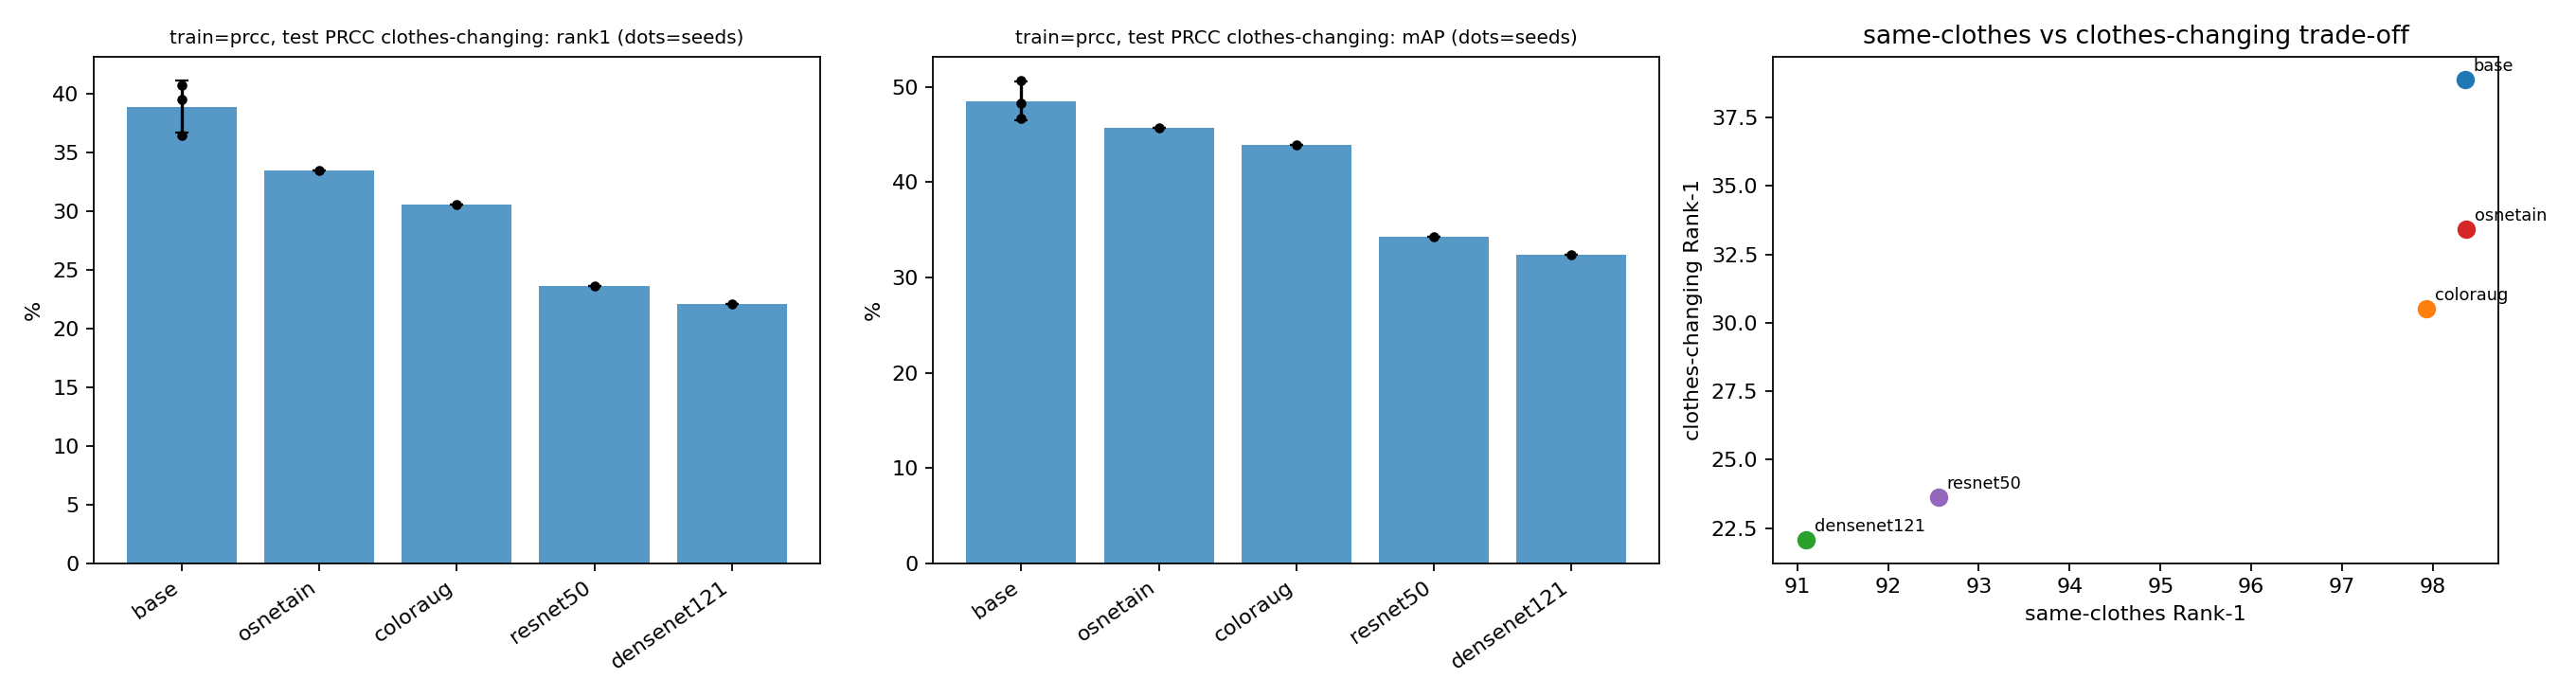

In [ ]:
!RES=results TRAIN=prcc python analysis.py
from IPython.display import Image, display
display(Image('results/figures/fig_models.png'))

In [ ]:
import os, glob, pandas as pd
os.system('ln -sfn /content/drive/MyDrive/ccreid/runs /content/cc-reid-uncertainty/runs')
rows = []
for d in sorted(glob.glob('/content/cc-reid-uncertainty/runs/*')):
    log = os.path.join(d, 'log.csv')
    ep = len(pd.read_csv(log)) if os.path.exists(log) else 0
    rows.append((os.path.basename(d), 'DONE' if os.path.exists(d + '/last.pt') else ('partial (resume ho sakta hai)' if os.path.exists(d + '/ckpt.pt') else 'no checkpoint'), ep))
print(pd.DataFrame(rows, columns=['run', 'status', 'epochs_logged']).to_string(index=False))

                  run                        status  epochs_logged
       market_base_s0                          DONE             30
market_densenet121_s0                          DONE             30
   market_osnetain_s0                          DONE             30
   market_resnet50_s0                          DONE             30
         prcc_base_s0                          DONE             30
         prcc_base_s1                          DONE             30
         prcc_base_s2                          DONE             30
     prcc_coloraug_s0                          DONE             30
  prcc_densenet121_s0                          DONE             30
     prcc_osnetain_s0                          DONE             30
     prcc_osnetain_s1 partial (resume ho sakta hai)             23
     prcc_resnet50_s0                          DONE             30


In [1]:
import torch
print('GPU:', torch.cuda.is_available())

GPU: True
